<a href="https://colab.research.google.com/github/freudandprejudice/A-Neurocognitive-Study-of-SIMKAP-Multitasking-Workload-with-EEG/blob/main/Copy_of_Allen_SDK_Prajwals_Version.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Imports

In [ ]:
!python --version

Python 3.11.13


In [ ]:
# Run this in a fresh Colab Python 3.11 runtime, ignore the errors and restart the session. After the restart, don't run this cell again.

!pip uninstall -y allensdk brain_observatory_utilities pynwb hdmf ndx-events

!pip install -q \
  "numpy<1.24" \
  "pandas==1.5.3" \
  "scipy<1.11" \
  "xarray<2023.2.0"

!pip install -q \
  "hdmf==3.14.6" \
  "pynwb==2.8.3" \
  "allensdk==2.16.2" \
  "brain_observatory_utilities==0.5.1" \
  "seaborn"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 92.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.1/17.1 MB 71.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 34.1/34.1 MB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 973.1/973.1 kB 38.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 1.5.3 which is incompatible.
albucore 0.0.24 requires numpy>=1.24.4, but you have numpy 1.23.5 which is incompatible.
albumentations 2.0.8 requires numpy>=1.24.4, but you have numpy 1.23.5 which is incompatible.
bigframes 2.10.0 requires numpy>=1.24.0, but you have numpy 1.23.5 which is incompatible.
blosc2 3.5.1 requires numpy>=1.26, but you have numpy 1.23.5 w

In [ ]:
import os
import scipy
import hdmf
import pynwb
import allensdk
import numpy as np
import pandas as pd
from tqdm import tqdm
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.manifold import TSNE

import brain_observatory_utilities.datasets.optical_physiology.data_formatting as ophys_formatting
import brain_observatory_utilities.utilities.general_utilities as utilities

from allensdk.brain_observatory.behavior.behavior_project_cache import VisualBehaviorOphysProjectCache
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scipy:", scipy.__version__)
print("hdmf:", hdmf.__version__)
print("pynwb:", pynwb.__version__)
print("allensdk:", allensdk.__version__)

numpy: 1.23.5
pandas: 1.5.3
scipy: 1.10.1
hdmf: 3.14.6
pynwb: 2.8.3
allensdk: 2.16.2


# Loading data

In [ ]:
pd.set_option('display.max_columns', 500)
# this line may be needed if you run into Error in pandas query function
# Otherwise set the engine to python in queries made throughout the book
# pd.DataFrame.query = lambda self, expr, **kwargs: self.query(expr, engine='python', **kwargs)

In [ ]:
data_storage_directory = "./temp"  # Note: this path must exist on your local drive
cache = VisualBehaviorOphysProjectCache.from_s3_cache(cache_dir=data_storage_directory)

ophys_session_table.csv: 100%|██████████| 247k/247k [00:00<00:00, 1.69MMB/s] 
behavior_session_table.csv: 100%|██████████| 1.59M/1.59M [00:00<00:00, 8.58MMB/s]
ophys_experiment_table.csv: 100%|██████████| 657k/657k [00:00<00:00, 3.23MMB/s] 
ophys_cells_table.csv: 100%|██████████| 4.28M/4.28M [00:00<00:00, 12.7MMB/s]
/usr/local/lib/python3.11/dist-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_block_name`.

The data that was available in previous releases are stored in the block name containing 'change_detection' and can be accessed in the pandas table by using: 
	`stimulus_

In [ ]:
session_table = cache.get_ophys_session_table()
ophys_experiment_table = cache.get_ophys_experiment_table()

In [ ]:
print(
    ophys_experiment_table["experience_level"]
    .value_counts(dropna=False)
)

Familiar    990
Novel >1    711
Novel 1     235
Name: experience_level, dtype: int64


In [ ]:
ophys_experiment_table.head()

,behavior_session_id,ophys_session_id,ophys_container_id,mouse_id,indicator,full_genotype,driver_line,cre_line,reporter_line,sex,age_in_days,imaging_depth,targeted_structure,targeted_imaging_depth,imaging_plane_group,project_code,session_type,session_number,image_set,behavior_type,passive,experience_level,prior_exposures_to_session_type,prior_exposures_to_image_set,prior_exposures_to_omissions,date_of_acquisition,equipment_name,published_at,isi_experiment_id,file_id
ophys_experiment_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
951980471,951520319,951410079,1018028342,457841,GCaMP6f,Sst-IRES-Cre/wt;Ai148(TIT2L-GC6f-ICL-tTA2)/wt,[Sst-IRES-Cre],Sst-IRES-Cre,Ai148(TIT2L-GC6f-ICL-tTA2),F,206,150,VISp,150,0,VisualBehaviorMultiscope,OPHYS_1_images_A,1,A,active_behavior,False,Familiar,0,65,0,2019-09-20 09:59:38.837000+00:00,MESO.1,2021-03-25,848974280,0
951980473,951520319,951410079,1018028345,457841,GCaMP6f,Sst-IRES-Cre/wt;Ai148(TIT2L-GC6f-ICL-tTA2)/wt,[Sst-IRES-Cre],Sst-IRES-Cre,Ai148(TIT2L-GC6f-ICL-tTA2),F,206,225,VISp,225,0,VisualBehaviorMultiscope,OPHYS_1_images_A,1,A,active_behavior,False,Familiar,0,65,0,2019-09-20 09:59:38.837000+00:00,MESO.1,2021-03-25,848974280,1
951980475,951520319,951410079,1018028339,457841,GCaMP6f,Sst-IRES-Cre/wt;Ai148(TIT2L-GC6f-ICL-tTA2)/wt,[Sst-IRES-Cre],Sst-IRES-Cre,Ai148(TIT2L-GC6f-ICL-tTA2),F,206,75,VISp,75,1,VisualBehaviorMultiscope,OPHYS_1_images_A,1,A,active_behavior,False,Familiar,0,65,0,2019-09-20 09:59:38.837000+00:00,MESO.1,2021-03-25,848974280,2
951980479,951520319,951410079,1018028354,457841,GCaMP6f,Sst-IRES-Cre/wt;Ai148(TIT2L-GC6f-ICL-tTA2)/wt,[Sst-IRES-Cre],Sst-IRES-Cre,Ai148(TIT2L-GC6f-ICL-tTA2),F,206,150,VISl,150,2,VisualBehaviorMultiscope,OPHYS_1_images_A,1,A,active_behavior,False,Familiar,0,65,0,2019-09-20 09:59:38.837000+00:00,MESO.1,2021-03-25,848974280,3
951980481,951520319,951410079,1018028357,457841,GCaMP6f,Sst-IRES-Cre/wt;Ai148(TIT2L-GC6f-ICL-tTA2)/wt,[Sst-IRES-Cre],Sst-IRES-Cre,Ai148(TIT2L-GC6f-ICL-tTA2),F,206,225,VISl,225,2,VisualBehaviorMultiscope,OPHYS_1_images_A,1,A,active_behavior,False,Familiar,0,65,0,2019-09-20 09:59:38.837000+00:00,MESO.1,2021-03-25,848974280,4


In [ ]:
session_metadata = (
    ophys_experiment_table.reset_index()[
        [
            "ophys_experiment_id",
            "ophys_session_id",
            "ophys_container_id",
            "experience_level",
            "session_type",
            "targeted_structure",
            "cre_line"
        ]
    ]
    .drop_duplicates()
)

In [ ]:
print(ophys_experiment_table['targeted_structure'].unique())

['VISp' 'VISl' 'VISal' 'VISam']


In [ ]:
print(ophys_experiment_table['cre_line'].unique())

['Sst-IRES-Cre' 'Vip-IRES-Cre' 'Slc17a7-IRES2-Cre']


In [ ]:
valid_container_ids = session_metadata["ophys_container_id"].unique()
OPHYS_CONTAINER_ID = valid_container_ids[1]

container_sessions = session_metadata[
    session_metadata["ophys_container_id"] == OPHYS_CONTAINER_ID
].sort_values("ophys_session_id")

display(container_sessions)

,ophys_experiment_id,ophys_session_id,ophys_container_id,experience_level,session_type,targeted_structure,cre_line
1,951980473,951410079,1018028345,Familiar,OPHYS_1_images_A,VISp,Sst-IRES-Cre
7,953659743,952430817,1018028345,Familiar,OPHYS_2_images_A_passive,VISp,Sst-IRES-Cre
12,958527471,954954402,1018028345,Familiar,OPHYS_3_images_A,VISp,Sst-IRES-Cre
19,956941844,955775716,1018028345,Familiar,OPHYS_3_images_A,VISp,Sst-IRES-Cre
22,957759564,957020350,1018028345,Novel 1,OPHYS_4_images_B,VISp,Sst-IRES-Cre
29,958741222,958105827,1018028345,Familiar,OPHYS_3_images_A,VISp,Sst-IRES-Cre
34,959388790,958772311,1018028345,Novel >1,OPHYS_5_images_B_passive,VISp,Sst-IRES-Cre
41,960410026,959458018,1018028345,Novel >1,OPHYS_6_images_B,VISp,Sst-IRES-Cre


# Filtering for container id and trials
Experience level novel and novel >1, cre_line = Slc17a7-IRES2-Cre, targeted structure = VISp
Hit trials only

In [ ]:
# Search for an OPHYS_CONTAINER_ID that meets all criteria
found_container_id = None

for container_id in valid_container_ids:
    current_container_sessions = session_metadata[
        session_metadata["ophys_container_id"] == container_id
    ].sort_values("ophys_session_id")

    novel_1_filtered = current_container_sessions[
        (current_container_sessions["experience_level"] == "Novel 1") &
        (current_container_sessions["cre_line"] == "Slc17a7-IRES2-Cre") &
        (current_container_sessions["targeted_structure"] == "VISp")
    ]

    novel_plus_filtered = current_container_sessions[
        (current_container_sessions["experience_level"] == "Novel >1") &
        (current_container_sessions["cre_line"] == "Slc17a7-IRES2-Cre") &
        (current_container_sessions["targeted_structure"] == "VISp")
    ]

    if not novel_1_filtered.empty and not novel_plus_filtered.empty:
        found_container_id = container_id
        break

if found_container_id is not None:
    print(f"Found a suitable OPHYS_CONTAINER_ID: {found_container_id}")
    # Update the OPHYS_CONTAINER_ID variable to the found one
    OPHYS_CONTAINER_ID = found_container_id
    # Display sessions for the new container
    container_sessions = session_metadata[
        session_metadata["ophys_container_id"] == OPHYS_CONTAINER_ID
    ].sort_values("ophys_session_id")
    display(container_sessions)
    print("Please run the following cells starting from 'uIPhafoXlrUq' to load and filter data with the new container ID.")
else:
    print("No OPHYS_CONTAINER_ID found that contains both 'Novel 1' and 'Novel >1' experiments with 'Slc17a7-IRES2-Cre' and 'VISp'.")
    print("You may need to adjust your filtering criteria or select a different container manually.")

Found a suitable OPHYS_CONTAINER_ID: 876693090


,ophys_experiment_id,ophys_session_id,ophys_container_id,experience_level,session_type,targeted_structure,cre_line
66,877696762,877103886,876693090,Familiar,OPHYS_2_images_A_passive,VISp,Slc17a7-IRES2-Cre
67,879332693,878436988,876693090,Familiar,OPHYS_1_images_A,VISp,Slc17a7-IRES2-Cre
68,880375092,879719132,876693090,Novel 1,OPHYS_4_images_B,VISp,Slc17a7-IRES2-Cre
69,881881171,881071629,876693090,Novel >1,OPHYS_6_images_B,VISp,Slc17a7-IRES2-Cre
70,882935355,882620042,876693090,Novel >1,OPHYS_6_images_B,VISp,Slc17a7-IRES2-Cre
71,884218326,883349458,876693090,Novel >1,OPHYS_5_images_B_passive,VISp,Slc17a7-IRES2-Cre


Please run the following cells starting from 'uIPhafoXlrUq' to load and filter data with the new container ID.


In [ ]:
novel_1_rows = container_sessions[
    (container_sessions["experience_level"] == "Novel 1") &
    (container_sessions["cre_line"] == "Slc17a7-IRES2-Cre") &
    (container_sessions["targeted_structure"] == "VISp")
]

novel_plus_rows = container_sessions[
    (container_sessions["experience_level"] == "Novel >1") &
    (container_sessions["cre_line"] == "Slc17a7-IRES2-Cre") &
    (container_sessions["targeted_structure"] == "VISp")
]

if novel_1_rows.empty:
    raise ValueError(f"No Novel 1 experiment found for OPHYS_CONTAINER_ID: {OPHYS_CONTAINER_ID} with the specified cre_line and targeted_structure.")

if novel_plus_rows.empty:
    raise ValueError(f"No Novel >1 experiment found for OPHYS_CONTAINER_ID: {OPHYS_CONTAINER_ID} with the specified cre_line and targeted_structure.")

display(novel_1_rows)
display(novel_plus_rows)


# There may be multiple experiments within this container. For now, use the first one.
novel_1_experiment_id = int(
    novel_1_rows.iloc[0]["ophys_experiment_id"]
)
novel_plus_experiment_id = int(
    novel_plus_rows.iloc[0]["ophys_experiment_id"]
)

print("Novel 1 experiment:", novel_1_experiment_id)
print("Novel >1 experiment:", novel_plus_experiment_id)

,ophys_experiment_id,ophys_session_id,ophys_container_id,experience_level,session_type,targeted_structure,cre_line
68,880375092,879719132,876693090,Novel 1,OPHYS_4_images_B,VISp,Slc17a7-IRES2-Cre


,ophys_experiment_id,ophys_session_id,ophys_container_id,experience_level,session_type,targeted_structure,cre_line
69,881881171,881071629,876693090,Novel >1,OPHYS_6_images_B,VISp,Slc17a7-IRES2-Cre
70,882935355,882620042,876693090,Novel >1,OPHYS_6_images_B,VISp,Slc17a7-IRES2-Cre
71,884218326,883349458,876693090,Novel >1,OPHYS_5_images_B_passive,VISp,Slc17a7-IRES2-Cre


Novel 1 experiment: 880375092
Novel >1 experiment: 881881171


In [ ]:
novel_1_experiment = cache.get_behavior_ophys_experiment(
    novel_1_experiment_id
)

novel_plus_experiment = cache.get_behavior_ophys_experiment(
    novel_plus_experiment_id
)

behavior_ophys_experiment_880375092.nwb: 100%|██████████| 2.67G/2.67G [02:38<00:00, 16.8MMB/s]
/usr/local/lib/python3.11/dist-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.6.0-alpha because version 2.7.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
behavior_ophys_experiment_881881171.nwb: 100%|██████████| 2.42G/2.42G [03:25<00:00, 11.8MMB/s]
/usr/local/lib/python3.11/dist-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.6.0-alpha because version 2.7.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


In [ ]:
print('Novel 1 experiment ophys timestamps (first 5):')
display(novel_1_experiment.ophys_timestamps[:5])

novel_1_experiment.trials.head()

Novel 1 experiment ophys timestamps (first 5):


array([2.23825, 2.27056, 2.30287, 2.33517, 2.36748])

,start_time,stop_time,initial_image_name,change_image_name,is_change,change_time,go,catch,lick_times,response_time,response_latency,reward_time,reward_volume,hit,false_alarm,miss,correct_reject,aborted,auto_rewarded,change_frame,trial_length
trials_id,,,,,,,,,,,,,,,,,,,,,
0,307.84662,308.26361,im000,im000,False,NaN,False,False,[307.94671],NaN,NaN,NaN,0.0,False,False,False,False,True,False,-99,0.41699
1,308.59721,310.44874,im000,im000,False,NaN,False,False,"[309.66477, 309.79821, 309.94832, 310.1318]",NaN,NaN,NaN,0.0,False,False,False,False,True,False,-99,1.85153
2,310.84907,312.81733,im000,im000,False,NaN,False,False,"[310.93246, 311.13262, 311.28274, 311.48292, 3...",NaN,NaN,NaN,0.0,False,False,False,False,True,False,-99,1.96826
3,313.10091,314.66884,im000,im000,False,NaN,False,False,"[313.21765, 313.50157, 313.66831, 313.85179, 3...",NaN,NaN,NaN,0.0,False,False,False,False,True,False,-99,1.56793
4,315.35273,316.15340,im000,im000,False,NaN,False,False,"[315.48617, 315.66967, 315.83648, 316.17008, 3...",NaN,NaN,NaN,0.0,False,False,False,False,True,False,-99,0.80067


In [ ]:
print('Novel plus experiment ophys timestamps (first 5):')
display(novel_plus_experiment.ophys_timestamps[:5])

novel_plus_experiment.trials.head()

Novel plus experiment ophys timestamps (first 5):


array([2.28639, 2.31869, 2.351  , 2.38331, 2.41561])

,start_time,stop_time,initial_image_name,change_image_name,is_change,change_time,go,catch,lick_times,response_time,response_latency,reward_time,reward_volume,hit,false_alarm,miss,correct_reject,aborted,auto_rewarded,change_frame,trial_length
trials_id,,,,,,,,,,,,,,,,,,,,,
0,307.56333,309.31480,im000,im000,False,NaN,False,False,"[308.78099, 308.9978]",NaN,NaN,NaN,0.000,False,False,False,False,True,False,-99,1.75147
1,309.81515,310.18214,im000,im000,False,NaN,False,False,[309.86519],NaN,NaN,NaN,0.000,False,False,False,False,True,False,-99,0.36699
2,310.56576,312.03364,im000,im000,False,NaN,False,False,[311.71672],NaN,NaN,NaN,0.000,False,False,False,False,True,False,-99,1.46788
3,312.06700,319.33959,im000,im031,True,315.090936,False,False,"[315.92012, 316.22038, 316.47058, 316.62072, 3...",315.92012,0.829184,315.21958,0.005,False,False,False,False,False,True,18436,7.27259
4,319.57313,320.60731,im031,im031,False,NaN,False,False,"[319.67321, 319.78999, 319.99013, 320.14024, 3...",NaN,NaN,NaN,0.000,False,False,False,False,True,False,-99,1.03418


In [ ]:
novel_1_hits = novel_1_experiment.trials[
    novel_1_experiment.trials["hit"] == True
]
novel_1_hits.head()


,start_time,stop_time,initial_image_name,change_image_name,is_change,change_time,go,catch,lick_times,response_time,response_latency,reward_time,reward_volume,hit,false_alarm,miss,correct_reject,aborted,auto_rewarded,change_frame,trial_length
trials_id,,,,,,,,,,,,,,,,,,,,,
125,613.34627,623.62096,im075,im000,True,619.372328,True,False,"[620.08471, 620.16812, 620.31824, 620.435, 620...",620.08471,0.712382,620.08471,0.007,True,False,False,False,False,False,36661,10.27469
127,625.35599,632.62831,im000,im075,True,628.379678,True,False,"[629.10877, 629.37565, 629.52576, 629.62584, 6...",629.10877,0.729092,629.10877,0.007,True,False,False,False,False,False,37201,7.27232
129,635.11367,642.38627,im075,im106,True,638.137628,True,False,"[638.74994, 638.86673, 638.98349, 639.08357, 6...",638.74994,0.612312,638.74994,0.007,True,False,False,False,False,False,37786,7.27260
137,675.64673,687.40634,im073,im075,True,683.174398,True,False,"[683.8034, 684.10365, 684.32049, 684.43728, 68...",683.80340,0.629002,683.80340,0.007,True,False,False,False,False,False,40486,11.75961
139,689.15777,698.66553,im075,im031,True,694.433578,True,False,"[695.14599, 695.29616, 695.39619, 695.49627, 6...",695.14599,0.712412,695.14599,0.007,True,False,False,False,False,False,41161,9.50776


In [ ]:
novel_plus_hits = novel_plus_experiment.trials[
    novel_plus_experiment.trials["hit"] == True
]
novel_plus_hits.head()

,start_time,stop_time,initial_image_name,change_image_name,is_change,change_time,go,catch,lick_times,response_time,response_latency,reward_time,reward_volume,hit,false_alarm,miss,correct_reject,aborted,auto_rewarded,change_frame,trial_length
trials_id,,,,,,,,,,,,,,,,,,,,,
130,559.01849,568.52624,im035,im031,True,564.294296,True,False,"[564.87327, 564.95668, 565.20687, 565.32364, 5...",564.87327,0.578974,564.87327,0.007,True,False,False,False,False,False,33376,9.50775
140,640.08465,651.09363,im073,im035,True,646.861676,True,False,"[647.57407, 647.72419, 647.85766, 648.07451, 6...",647.57407,0.712394,647.57407,0.007,True,False,False,False,False,False,38326,11.00898
142,655.09689,662.35281,im035,im045,True,658.120856,True,False,"[658.64979, 658.73321, 658.98338, 659.10016, 6...",658.64979,0.528934,658.64979,0.007,True,False,False,False,False,False,39001,7.25592
168,812.72549,824.48509,im054,im045,True,820.253156,True,False,"[820.89885, 821.24914, 821.46598, 821.68281, 8...",820.89885,0.645694,820.89885,0.007,True,False,False,False,False,False,48721,11.75960
171,826.98714,834.99366,im045,im035,True,830.761726,True,False,"[831.34104, 831.54119, 831.65787, 831.89138, 8...",831.34104,0.579314,831.34104,0.007,True,False,False,False,False,False,49351,8.00652


In [ ]:
print(len(novel_1_hits))
print(len(novel_plus_hits))

67
72


# Extracting All Hit Trials from All Relevant Experiments

To analyze all hit trials across all containers that match our criteria, we first need to identify all `ophys_experiment_id`s. We will then load each of these experiments and combine their 'hit' trials into single DataFrames for 'Novel 1' and 'Novel >1' conditions. This will allow for a more comprehensive analysis.


In [ ]:
# Filter `session_metadata` to get all experiment IDs matching the criteria
all_filtered_experiments = session_metadata[
    (session_metadata["cre_line"] == "Slc17a7-IRES2-Cre") &
    (session_metadata["targeted_structure"] == "VISp")
]

# Get experiment IDs for 'Novel 1' sessions
all_novel_1_experiment_ids = all_filtered_experiments[
    all_filtered_experiments["experience_level"] == "Novel 1"
]["ophys_experiment_id"].tolist()

# Get experiment IDs for 'Novel >1' sessions
all_novel_plus_experiment_ids = all_filtered_experiments[
    all_filtered_experiments["experience_level"] == "Novel >1"
]["ophys_experiment_id"].tolist()

print(f"Found {len(all_novel_1_experiment_ids)} Novel 1 experiment IDs matching criteria.")
print(f"Found {len(all_novel_plus_experiment_ids)} Novel >1 experiment IDs matching criteria.")

# Load all identified experiments
all_novel_1_experiments_list = []
print("Loading Novel 1 experiments...")
for exp_id in all_novel_1_experiment_ids:
    all_novel_1_experiments_list.append(cache.get_behavior_ophys_experiment(exp_id))

all_novel_plus_experiments_list = []
print("Loading Novel >1 experiments...")
for exp_id in all_novel_plus_experiment_ids:
    all_novel_plus_experiments_list.append(cache.get_behavior_ophys_experiment(exp_id))

print(f"Loaded {len(all_novel_1_experiments_list)} Novel 1 experiments.")
print(f"Loaded {len(all_novel_plus_experiments_list)} Novel >1 experiments.")


Found 63 Novel 1 experiment IDs matching criteria.
Found 187 Novel >1 experiment IDs matching criteria.
Loading Novel 1 experiments...


/usr/local/lib/python3.11/dist-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.6.0-alpha because version 2.7.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


In [ ]:
# Combine all 'hit' trials from the loaded experiments
all_novel_1_hits_combined = pd.DataFrame()
for exp in all_novel_1_experiments_list:
    hits = exp.trials[exp.trials["hit"] == True]
    all_novel_1_hits_combined = pd.concat([all_novel_1_hits_combined, hits])

all_novel_plus_hits_combined = pd.DataFrame()
for exp in all_novel_plus_experiments_list:
    hits = exp.trials[exp.trials["hit"] == True]
    all_novel_plus_hits_combined = pd.concat([all_novel_plus_hits_combined, hits])

print(f"Total Novel 1 hits combined: {len(all_novel_1_hits_combined)}")
display(all_novel_1_hits_combined.head())

print(f"Total Novel >1 hits combined: {len(all_novel_plus_hits_combined)}")
display(all_novel_plus_hits_combined.head())

# The variables `novel_1_hits` and `novel_plus_hits` are now `all_novel_1_hits_combined` and `all_novel_plus_hits_combined`
# Downstream cells that used `novel_1_hits` or `novel_plus_hits` will need to be updated to use these new combined dataframes.

# Raster plots and Peri-stimulus histograms

In [ ]:
def get_peri_event_traces_for_cell(experiment_obj, trials_df, cell_id, event_type='change_time', window_pre_s=2, window_post_s=4):
    """
    Extracts peri-event dF/F traces for a specific cell across multiple trials.

    Args:
        experiment_obj: The BehaviorOphysExperiment object.
        trials_df (pd.DataFrame): DataFrame of trials (e.g., novel_1_hits).
        cell_id (int): The ID of the cell to extract traces for.
        event_type (str): Column name in trials_df indicating the event time (e.g., 'change_time').
        window_pre_s (float): Time in seconds before the event to include in the trace.
        window_post_s (float): Time in seconds after the event to include in the trace.

    Returns:
        pd.DataFrame: A DataFrame where each row corresponds to a trial, containing
                      'stimulus_presentations_id', 'trace_timestamps' (relative to event)
                      and 'trace' (dF/F values).
    """
    ophys_timestamps = np.asarray(experiment_obj.ophys_timestamps)
    dff_traces_all_cells = experiment_obj.dff_traces

    if cell_id not in dff_traces_all_cells.index:
        print(f"Cell ID {cell_id} not found in dff_traces for this experiment.")
        return pd.DataFrame(columns=['stimulus_presentations_id', 'trace_timestamps', 'trace'])

    cell_dff_trace_data = np.asarray(dff_traces_all_cells.loc[cell_id, 'dff'])

    extracted_traces = []
    for trial_idx, trial_row in trials_df.iterrows():
        event_time = trial_row.get(event_type)
        if pd.isna(event_time):
            continue

        start_window = event_time - window_pre_s
        end_window = event_time + window_post_s

        mask = (ophys_timestamps >= start_window) & (ophys_timestamps < end_window)

        if not np.any(mask):
            continue

        relative_timestamps = ophys_timestamps[mask] - event_time
        dff_segment = cell_dff_trace_data[mask]

        extracted_traces.append({
            'stimulus_presentations_id': trial_idx,
            'trace_timestamps': relative_timestamps,
            'trace': dff_segment
        })

    if not extracted_traces:
        return pd.DataFrame(columns=['stimulus_presentations_id', 'trace_timestamps', 'trace'])

    # Removed the filtering for consistent length. All extracted traces are now included.
    final_presentation_ids = [item['stimulus_presentations_id'] for item in extracted_traces]
    final_timestamps_list = [item['trace_timestamps'] for item in extracted_traces]
    final_traces_list = [item['trace'] for item in extracted_traces]

    return pd.DataFrame({
        'stimulus_presentations_id': final_presentation_ids,
        'trace_timestamps': final_timestamps_list,
        'trace': final_traces_list
    })

In [ ]:
import numpy as np

# Ensure common_cell_ids is defined, in case a previous cell was skipped or the kernel was restarted.
if 'common_cell_ids' not in globals():
    print("Warning: common_cell_ids not found, attempting to re-initialize.")
    # These variables are assumed to be defined by successful execution of earlier cells.
    novel_1_cell_ids = novel_1_experiment.dff_traces.index.to_numpy()
    novel_plus_cell_ids = novel_plus_experiment.dff_traces.index.to_numpy()
    common_cell_ids = np.intersect1d(
        novel_1_cell_ids,
        novel_plus_cell_ids
    )
    print(f"Re-initialized common_cell_ids with {len(common_cell_ids)} matched cells.")

# Select a cell ID from the common_cell_ids to plot
selected_cell_id = common_cell_ids[0]

# Prepare data for Novel 1 hits
novel_1_hits_for_plot = get_peri_event_traces_for_cell(
    experiment_obj=novel_1_experiment,
    trials_df=novel_1_hits,
    cell_id=selected_cell_id,
    event_type='change_time'
)

# Prepare data for Novel >1 hits
novel_plus_hits_for_plot = get_peri_event_traces_for_cell(
    experiment_obj=novel_plus_experiment,
    trials_df=novel_plus_hits,
    cell_id=selected_cell_id,
    event_type='change_time'
)

print(f"Prepared {len(novel_1_hits_for_plot)} traces for Novel 1 hits (cell {selected_cell_id}).")
print(f"Prepared {len(novel_plus_hits_for_plot)} traces for Novel >1 hits (cell {selected_cell_id}).")

Re-initialized common_cell_ids with 326 matched cells.
Prepared 67 traces for Novel 1 hits (cell 1086539653).
Prepared 72 traces for Novel >1 hits (cell 1086539653).


In [ ]:
def plot_psth(data_subset, title, color_map='viridis'):
    """
    Plots the Peristimulus Time Histogram (PSTH) for a given data subset.
    Handles variable-length traces by truncating to the minimum common length.

    Args:
        data_subset (pd.DataFrame): DataFrame containing 'trace_timestamps' and 'trace'.
        title (str): Title for the plot.
        color_map (str): Matplotlib colormap to use for coloring lines.
    """
    plt.figure(figsize=(10, 6))

    if data_subset.empty:
        print(f"No data to plot for {title}")
        plt.close()
        return

    # Filter out empty traces and find the minimum length among remaining traces
    non_empty_traces_timestamps = [t for t in data_subset.trace_timestamps.values if len(t) > 0]
    non_empty_traces = [t for t in data_subset.trace.values if len(t) > 0]

    if not non_empty_traces:
        print(f"No valid traces of non-zero length found for {title}")
        plt.close()
        return

    min_length = min(len(t) for t in non_empty_traces)

    # Truncate all non-empty traces and their corresponding timestamps to the minimum length
    truncated_timestamps = [ts[:min_length] for ts in non_empty_traces_timestamps]
    truncated_traces = [tr[:min_length] for tr in non_empty_traces]

    # Ensure traces is a 2D array for mean calculation
    traces_array = np.array(truncated_traces)
    # Use the first truncated timestamps array as the common time base for plotting
    timestamps = truncated_timestamps[0]

    mean_trace = np.mean(traces_array, axis=0)
    std_err_trace = np.std(traces_array, axis=0) / np.sqrt(traces_array.shape[0])

    plt.plot(timestamps, mean_trace, label='Mean dF/F', color='blue')
    plt.fill_between(timestamps, mean_trace - std_err_trace, mean_trace + std_err_trace, color='blue', alpha=0.2, label='SEM')

    plt.title(f'PSTH: {title}')
    plt.xlabel('Time after event (sec)')
    plt.ylabel('Average dF/F')
    plt.axvline(0, color='gray', linestyle='--', alpha=0.7, label='Event onset')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


def plot_raster(data_subset, title, num_trials_to_plot=50, color_map='viridis'):
    """
    Plots a raster plot for a given data subset.
    Handles variable-length traces by plotting each trace with its own timestamps.

    Args:
        data_subset (pd.DataFrame): DataFrame containing 'trace_timestamps' and 'trace'.
        title (str): Title for the plot.
        num_trials_to_plot (int): Maximum number of trials to display in the raster plot.
        color_map (str): Matplotlib colormap to use for coloring lines.
    """
    plt.figure(figsize=(10, 8))

    if data_subset.empty:
        print(f"No data to plot for {title}")
        plt.close()
        return

    # Select a subset of trials to avoid overcrowding the plot
    plot_data = data_subset.copy() # Make a copy to avoid SettingWithCopyWarning
    unique_trials = plot_data.index.unique() # Use index (stimulus_presentations_id) for trials
    if len(unique_trials) > num_trials_to_plot:
        selected_indices = np.random.choice(unique_trials, num_trials_to_plot, replace=False)
        plot_data = plot_data.loc[selected_indices] # Use loc for selection

    # Sort by stimulus_presentations_id for consistent plotting order
    plot_data = plot_data.sort_values(by='stimulus_presentations_id')

    cmap = plt.get_cmap(color_map)
    colors = [cmap(i / len(plot_data)) for i in range(len(plot_data))]

    for i, (idx, row) in enumerate(plot_data.iterrows()):
        # Use row-specific timestamps for plotting
        plt.plot(row['trace_timestamps'], row['trace'], color=colors[i], alpha=0.7, linewidth=0.5)

    plt.title(f'Raster Plot: {title} (Showing {len(plot_data)} trials)')
    plt.xlabel('Time after event (sec)')
    plt.ylabel('dF/F')
    plt.axvline(0, color='gray', linestyle='--', alpha=0.7, label='Event onset')
    plt.grid(True, alpha=0.3)
    plt.show()

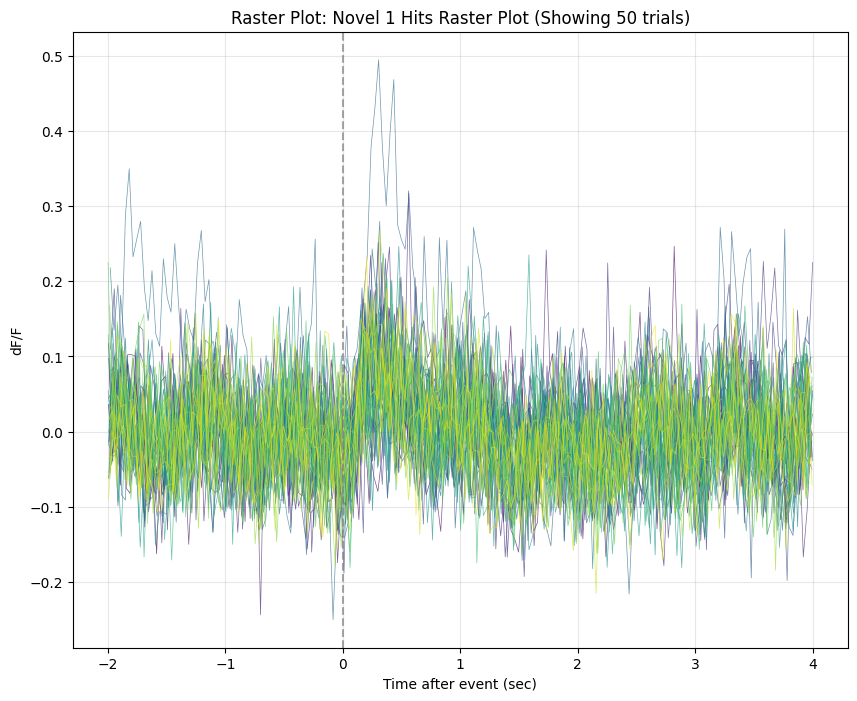

In [ ]:
plot_raster(novel_1_hits_for_plot, 'Novel 1 Hits Raster Plot')

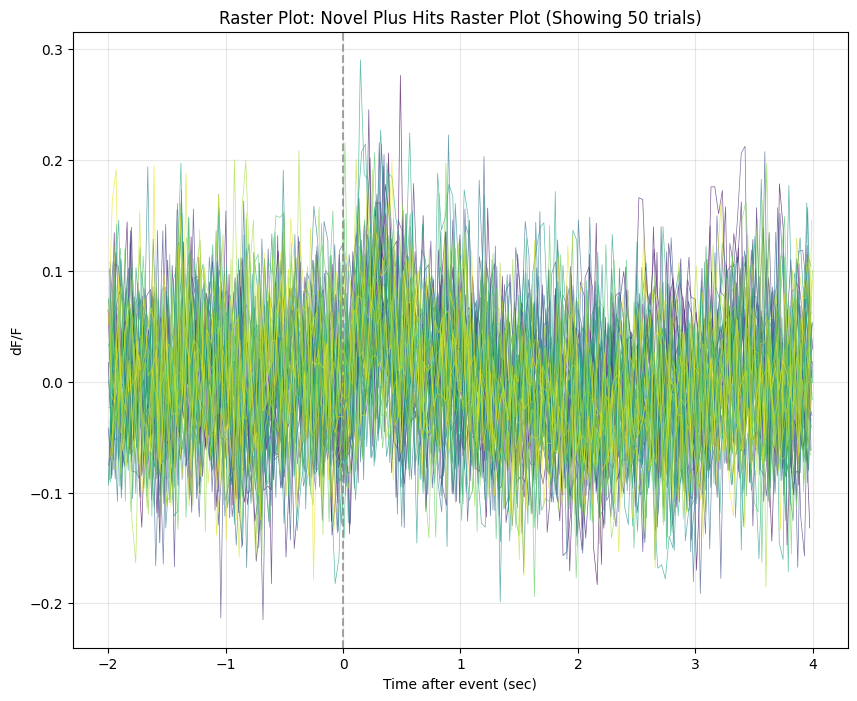

In [ ]:
plot_raster(novel_plus_hits_for_plot, 'Novel Plus Hits Raster Plot')

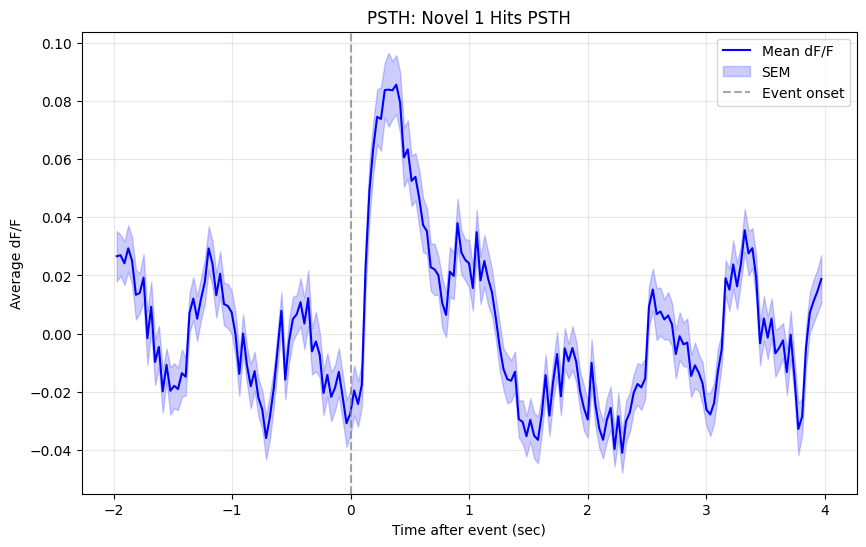

In [ ]:
plot_psth(novel_1_hits_for_plot, 'Novel 1 Hits PSTH')

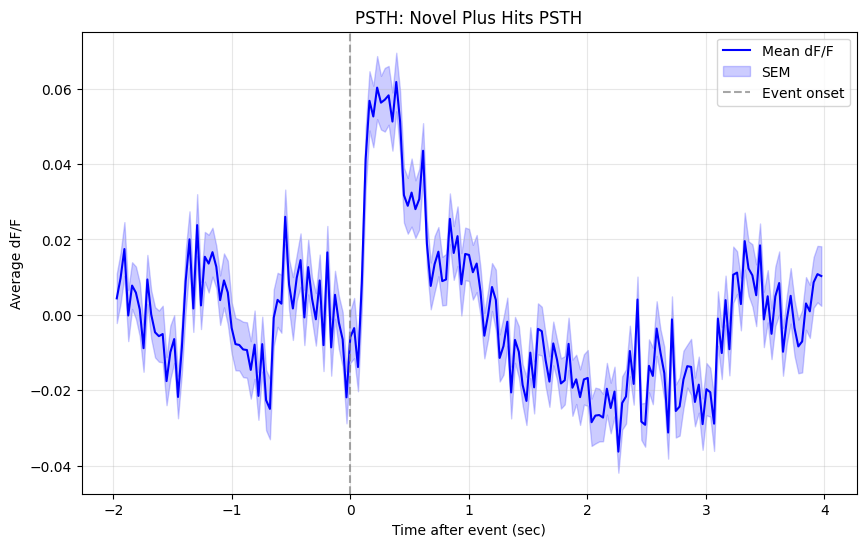

In [ ]:
plot_psth(novel_plus_hits_for_plot, 'Novel Plus Hits PSTH')

In [ ]:
!pip install oasis-deconv
from oasis.functions import deconvolve
from oasis.oasis_methods import oasisAR1

df_f_trace_novel = novel_1_experiment.dff_traces
df_f_trace_novel_plus = novel_plus_experiment.dff_traces

# Ensure selected_cell_id is available; assuming common_cell_ids is defined
selected_cell_id = common_cell_ids[0]

# Get the raw dF/F trace for the selected cell, convert to numpy array
raw_trace_novel = np.array(df_f_trace_novel.loc[selected_cell_id, 'dff'])
raw_trace_novel_plus = np.array(df_f_trace_novel_plus.loc[selected_cell_id, 'dff'])

# Calculate the correct framerate from experiment timestamps
ophys_framerate_novel = 1 / np.median(np.diff(novel_1_experiment.ophys_timestamps))
ophys_framerate_novel_plus = 1 / np.median(np.diff(novel_plus_experiment.ophys_timestamps))

# For simplicity, using the novel_1 framerate for both if they are very similar
# (which they were based on print_imaging_resolution output)
framerate = ophys_framerate_novel

# Perform deconvolution for the Novel 1 trace
denoised_trace_novel, spike_train_novel, baseline_novel, _g_novel, _lam_novel = deconvolve(raw_trace_novel, penalty=1, framerate=framerate)

# Perform deconvolution for the Novel >1 trace
denoised_trace_novel_plus, spike_train_novel_plus, baseline_novel_plus, _g_novel_plus, _lam_novel_plus = deconvolve(raw_trace_novel_plus, penalty=1, framerate=framerate)

firing_rate_novel = spike_train_novel * framerate
firing_rate_novel_plus = spike_train_novel_plus * framerate

time_axis_novel = np.arange(len(raw_trace_novel)) / framerate
time_axis_novel_plus = np.arange(len(raw_trace_novel_plus)) / framerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 10.6 MB/s eta 0:00:00


In [ ]:
def get_image_presentations(experiment):
    stimulus_presentations = experiment.stimulus_presentations.copy()

    # Keep only the image change-detection stimulus block.
    if "stimulus_block_name" in stimulus_presentations.columns:
        stimulus_presentations = stimulus_presentations[
            stimulus_presentations["stimulus_block_name"]
            .str.contains("change_detection", case=False, na=False)
        ]

    # Keep active task presentations when this column exists.
    if "active" in stimulus_presentations.columns:
        stimulus_presentations = stimulus_presentations[
            stimulus_presentations["active"] == True
        ]

    # Remove omitted presentations.
    if "omitted" in stimulus_presentations.columns:
        stimulus_presentations = stimulus_presentations[
            stimulus_presentations["omitted"] == False
        ]

    # Keep rows with an actual image label.
    stimulus_presentations = stimulus_presentations[
        stimulus_presentations["image_name"].notna()
    ]

    return stimulus_presentations


novel_1_presentations = get_image_presentations(
    novel_1_experiment
)

novel_plus_presentations = get_image_presentations(
    novel_plus_experiment
)

print("Novel 1 presentations:", len(novel_1_presentations))
print("Novel >1 presentations:", len(novel_plus_presentations))

Novel 1 presentations: 4633
Novel >1 presentations: 4632


In [ ]:
novel_1_images = set(
    novel_1_presentations["image_name"].unique()
)

novel_plus_images = set(
    novel_plus_presentations["image_name"].unique()
)

common_images = sorted(
    novel_1_images.intersection(novel_plus_images)
)

print("Images shared by Novel 1 and Novel >1:")
print(common_images)

if len(common_images) == 0:
    raise ValueError(
        "No common image labels were found between these experiments."
    )

Images shared by Novel 1 and Novel >1:
['im000', 'im031', 'im035', 'im045', 'im054', 'im073', 'im075', 'im106']


In [ ]:
# Automatically select the first common image.
# You can replace this with a specific label such as "im065".
IMAGE_NAME = common_images[0]

novel_1_image_presentations = novel_1_presentations[
    novel_1_presentations["image_name"] == IMAGE_NAME
].copy()

novel_plus_image_presentations = novel_plus_presentations[
    novel_plus_presentations["image_name"] == IMAGE_NAME
].copy()

print("Selected image:", IMAGE_NAME)

print(
    "Number of Novel 1 presentations:",
    len(novel_1_image_presentations)
)

print(
    "Number of Novel >1 presentations:",
    len(novel_plus_image_presentations)
)

display(novel_1_image_presentations.head())
display(novel_plus_image_presentations.head())

Selected image: im000
Number of Novel 1 presentations: 819
Number of Novel >1 presentations: 580


,stimulus_block,stimulus_block_name,image_index,image_name,movie_frame_index,duration,start_time,end_time,start_frame,end_frame,is_change,is_image_novel,omitted,movie_repeat,flashes_since_change,trials_id,active,stimulus_name,is_sham_change
stimulus_presentations_id,,,,,,,,,,,,,,,,,,,
1,1,change_detection_behavior,0,im000,-99,0.25021,307.868148,308.118358,17986,18001,False,True,False,-99,1,0,True,Natural_Images_Lum_Matched_set_ophys_6_2017,False
2,1,change_detection_behavior,0,im000,-99,0.25023,308.618738,308.868968,18031,18046,False,True,False,-99,2,1,True,Natural_Images_Lum_Matched_set_ophys_6_2017,False
3,1,change_detection_behavior,0,im000,-99,0.25020,309.369358,309.619558,18076,18091,False,True,False,-99,3,1,True,Natural_Images_Lum_Matched_set_ophys_6_2017,False
4,1,change_detection_behavior,0,im000,-99,0.25023,310.119968,310.370198,18121,18136,False,True,False,-99,4,1,True,Natural_Images_Lum_Matched_set_ophys_6_2017,False
5,1,change_detection_behavior,0,im000,-99,0.25018,310.870598,311.120778,18166,18181,False,True,False,-99,5,2,True,Natural_Images_Lum_Matched_set_ophys_6_2017,False


,stimulus_block,stimulus_block_name,image_index,image_name,movie_frame_index,duration,start_time,end_time,start_frame,end_frame,is_change,is_image_novel,omitted,movie_repeat,flashes_since_change,trials_id,active,stimulus_name,is_sham_change
stimulus_presentations_id,,,,,,,,,,,,,,,,,,,
1,1,change_detection_behavior,0,im000,-99,0.25019,307.584846,307.835036,17986,18001,False,False,False,-99,1,0,True,Natural_Images_Lum_Matched_set_ophys_6_2017,False
2,1,change_detection_behavior,0,im000,-99,0.25021,308.335466,308.585676,18031,18046,False,False,False,-99,2,0,True,Natural_Images_Lum_Matched_set_ophys_6_2017,False
3,1,change_detection_behavior,0,im000,-99,0.25026,309.086056,309.336316,18076,18091,False,False,False,-99,3,0,True,Natural_Images_Lum_Matched_set_ophys_6_2017,False
4,1,change_detection_behavior,0,im000,-99,0.25023,309.836666,310.086896,18121,18136,False,False,False,-99,4,1,True,Natural_Images_Lum_Matched_set_ophys_6_2017,False
5,1,change_detection_behavior,0,im000,-99,0.25022,310.587276,310.837496,18166,18181,False,False,False,-99,5,2,True,Natural_Images_Lum_Matched_set_ophys_6_2017,False


In [ ]:
def get_peri_event_deconv_traces(experiment_obj, deconv_trace, firing_rate_trace, image_presentations_df, time_axis, window_pre_s=0.5, window_post_s=0.5):
    """
    Extracts peri-event denoised dF/F and firing rate traces around stimulus presentations.

    Args:
        experiment_obj: The BehaviorOphysExperiment object (for ophys_timestamps).
        deconv_trace (np.ndarray): The full denoised dF/F trace.
        firing_rate_trace (np.ndarray): The full estimated firing rate trace.
        image_presentations_df (pd.DataFrame): DataFrame of stimulus presentations (e.g., novel_1_image_presentations).
        time_axis (np.ndarray): The time axis corresponding to deconv_trace and firing_rate_trace.
        window_pre_s (float): Time in seconds before the event to include in the trace.
        window_post_s (float): Time in seconds after the event to include in the trace.

    Returns:
        pd.DataFrame: A DataFrame where each row corresponds to a presentation, containing
                      'trace_timestamps' (relative to event), 'denoised_trace', and 'firing_rate'.
    """
    ophys_timestamps = np.asarray(experiment_obj.ophys_timestamps)

    extracted_traces = []
    for presentation_id, presentation_row in image_presentations_df.iterrows():
        event_time = presentation_row['start_time']

        start_window = event_time - window_pre_s
        end_window = event_time + window_post_s

        # Find indices in the global time_axis corresponding to the window
        mask = (time_axis >= start_window) & (time_axis < end_window)

        if not np.any(mask):
            continue

        relative_timestamps = time_axis[mask] - event_time
        denoised_segment = deconv_trace[mask]
        firing_rate_segment = firing_rate_trace[mask]

        extracted_traces.append({
            'stimulus_presentations_id': presentation_id,
            'trace_timestamps': relative_timestamps,
            'denoised_trace': denoised_segment,
            'firing_rate': firing_rate_segment
        })

    return pd.DataFrame(extracted_traces)


# Extract peri-event deconvolution traces for Novel 1
peri_event_deconv_novel = get_peri_event_deconv_traces(
    experiment_obj=novel_1_experiment,
    deconv_trace=denoised_trace_novel,
    firing_rate_trace=firing_rate_novel,
    image_presentations_df=novel_1_image_presentations,
    time_axis=time_axis_novel,
    window_pre_s=0.5,
    window_post_s=0.5
)

# Extract peri-event deconvolution traces for Novel >1
peri_event_deconv_novel_plus = get_peri_event_deconv_traces(
    experiment_obj=novel_plus_experiment,
    deconv_trace=denoised_trace_novel_plus,
    firing_rate_trace=firing_rate_novel_plus,
    image_presentations_df=novel_plus_image_presentations,
    time_axis=time_axis_novel_plus,
    window_pre_s=0.5,
    window_post_s=0.5
)

print(f"Extracted {len(peri_event_deconv_novel)} peri-event deconvolution traces for Novel 1.")
print(f"Extracted {len(peri_event_deconv_novel_plus)} peri-event deconvolution traces for Novel >1.")

Extracted 819 peri-event deconvolution traces for Novel 1.
Extracted 580 peri-event deconvolution traces for Novel >1.


In [ ]:
def plot_deconv_psth(data_subset, title):
    """
    Plots the Peri-Stimulus Time Histogram (PSTH) for denoised dF/F and firing rate.
    Handles variable-length traces by truncating to the minimum common length.

    Args:
        data_subset (pd.DataFrame): DataFrame containing 'trace_timestamps', 'denoised_trace', 'firing_rate'.
        title (str): Title for the plot.
    """
    plt.figure(figsize=(10, 8))

    if data_subset.empty:
        print(f"No data to plot for {title}")
        plt.close()
        return

    # Filter out empty traces and find the minimum length among remaining traces
    non_empty_timestamps = [t for t in data_subset.trace_timestamps.values if len(t) > 0]
    non_empty_denoised = [t for t in data_subset.denoised_trace.values if len(t) > 0]
    non_empty_firing_rate = [t for t in data_subset.firing_rate.values if len(t) > 0]

    if not non_empty_timestamps or not non_empty_denoised or not non_empty_firing_rate:
        print(f"No valid traces of non-zero length found for {title}")
        plt.close()
        return

    min_length = min(len(t) for t in non_empty_timestamps)

    # Truncate all non-empty traces and their corresponding timestamps to the minimum length
    truncated_timestamps = [ts[:min_length] for ts in non_empty_timestamps]
    truncated_denoised = [tr[:min_length] for tr in non_empty_denoised]
    truncated_firing_rate = [fr[:min_length] for fr in non_empty_firing_rate]

    # Convert to NumPy arrays for mean/SEM calculation
    denoised_array = np.array(truncated_denoised)
    firing_rate_array = np.array(truncated_firing_rate)
    timestamps = truncated_timestamps[0] # Use the first truncated timestamps array as the common time base

    # Calculate mean and SEM for denoised trace
    mean_denoised = np.mean(denoised_array, axis=0)
    sem_denoised = np.std(denoised_array, axis=0) / np.sqrt(denoised_array.shape[0])

    # Calculate mean and SEM for firing rate
    mean_firing_rate = np.mean(firing_rate_array, axis=0)
    sem_firing_rate = np.std(firing_rate_array, axis=0) / np.sqrt(firing_rate_array.shape[0])

    # Plot Denoised dF/F
    plt.subplot(2, 1, 1)
    plt.plot(timestamps, mean_denoised, label='Mean Denoised dF/F', color='blue')
    plt.fill_between(timestamps, mean_denoised - sem_denoised, mean_denoised + sem_denoised, color='blue', alpha=0.2, label='SEM')
    plt.axvline(0, color='gray', linestyle='--', alpha=0.7, label='Event onset')
    plt.ylabel('Denoised dF/F')
    plt.legend()
    plt.title(f'Deconvolution PSTH: {title}')
    plt.xlim(-0.5, 0.5) # Set x-axis limits to +/- 500 ms

    # Plot Estimated Firing Rate
    plt.subplot(2, 1, 2)
    plt.plot(timestamps, mean_firing_rate, label='Mean Estimated Firing Rate (Hz)', color='red')
    plt.fill_between(timestamps, mean_firing_rate - sem_firing_rate, mean_firing_rate + sem_firing_rate, color='red', alpha=0.2, label='SEM')
    plt.axvline(0, color='gray', linestyle='--', alpha=0.7)
    plt.xlabel('Time after event (sec)')
    plt.ylabel('Spikes / sec')
    plt.legend()
    plt.xlim(-0.5, 0.5) # Set x-axis limits to +/- 500 ms

    plt.tight_layout()
    plt.show()

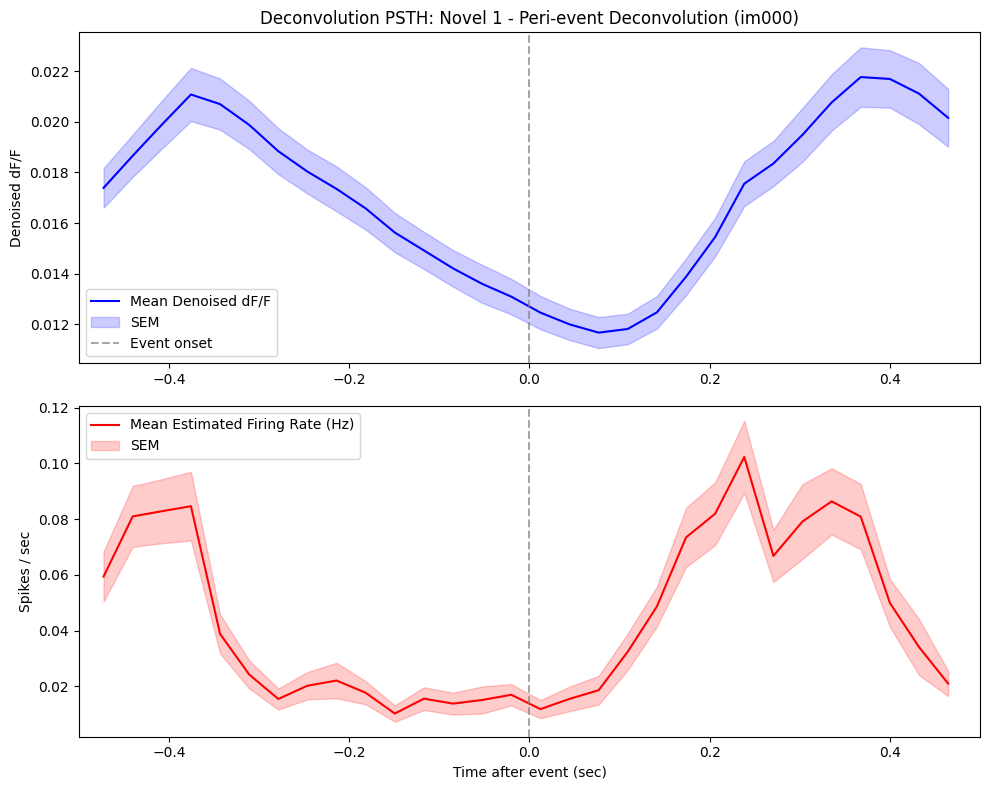

In [ ]:
plot_deconv_psth(peri_event_deconv_novel, 'Novel 1 - Peri-event Deconvolution (im000)')

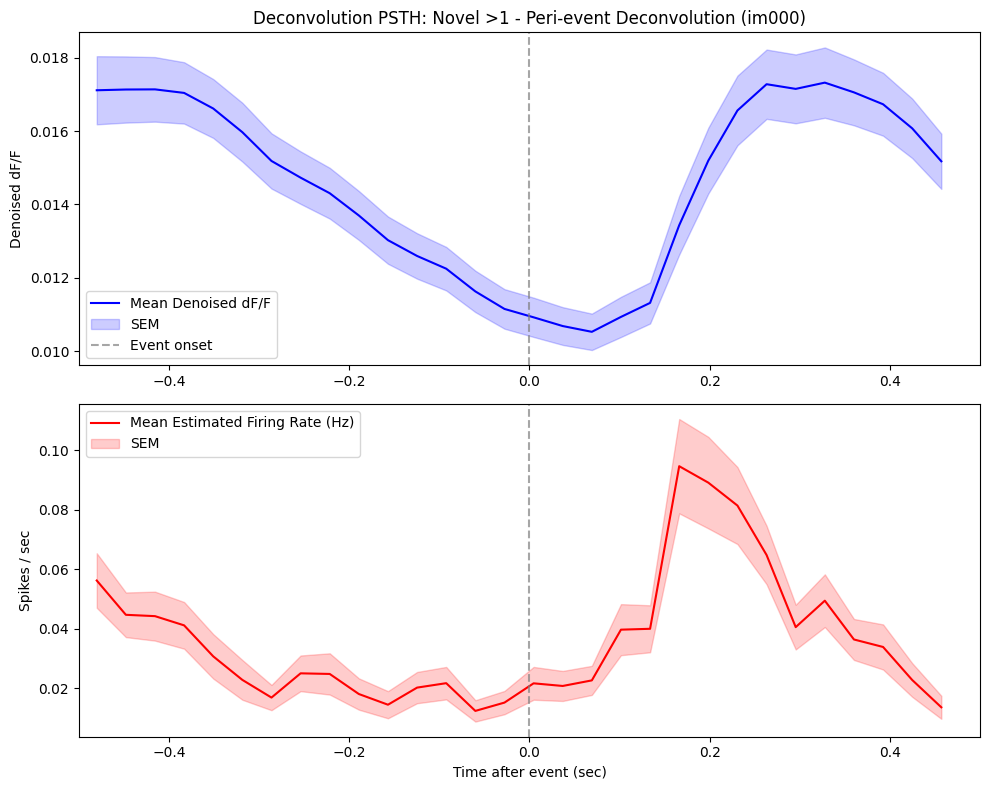

In [ ]:
plot_deconv_psth(peri_event_deconv_novel_plus, 'Novel >1 - Peri-event Deconvolution (im000)')

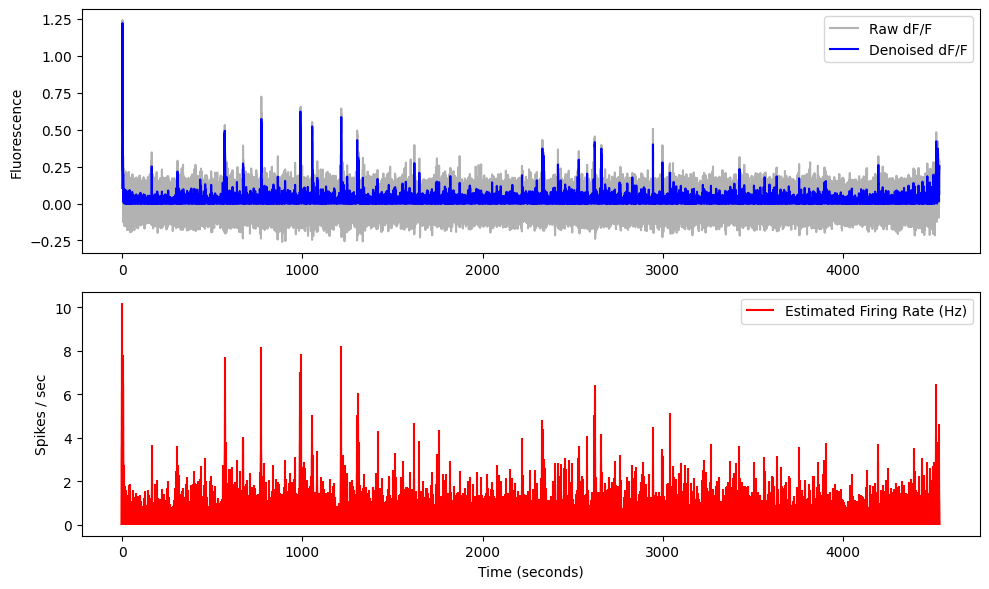

In [ ]:
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(time_axis_novel, raw_trace_novel, label='Raw dF/F', color='gray', alpha=0.6)
plt.plot(time_axis_novel, denoised_trace_novel, label='Denoised dF/F', color='blue')
plt.ylabel('Fluorescence')
plt.legend()

plt.subplot(2, 1, 2)
plt.vlines(time_axis_novel, 0, firing_rate_novel, color='red', label='Estimated Firing Rate (Hz)')
plt.xlabel('Time (seconds)')
plt.ylabel('Spikes / sec')
plt.legend()
plt.tight_layout()
plt.show()

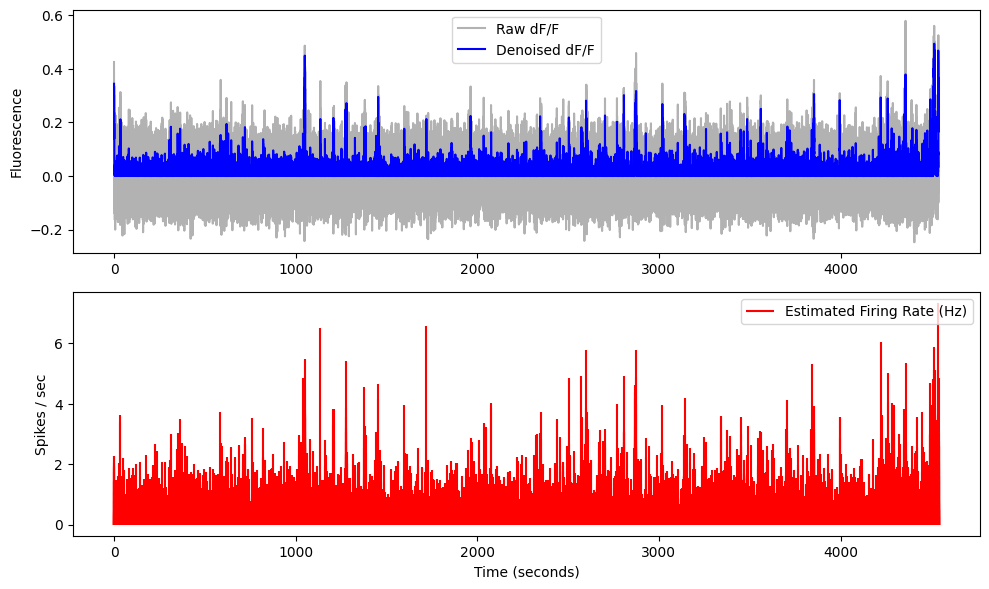

In [ ]:
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(time_axis_novel_plus, raw_trace_novel_plus, label='Raw dF/F', color='gray', alpha=0.6)
plt.plot(time_axis_novel_plus, denoised_trace_novel_plus, label='Denoised dF/F', color='blue')
plt.ylabel('Fluorescence')
plt.legend()

plt.subplot(2, 1, 2)
plt.vlines(time_axis_novel_plus, 0, firing_rate_novel_plus, color='red', label='Estimated Firing Rate (Hz)')
plt.xlabel('Time (seconds)')
plt.ylabel('Spikes / sec')
plt.legend()
plt.tight_layout()
plt.show()

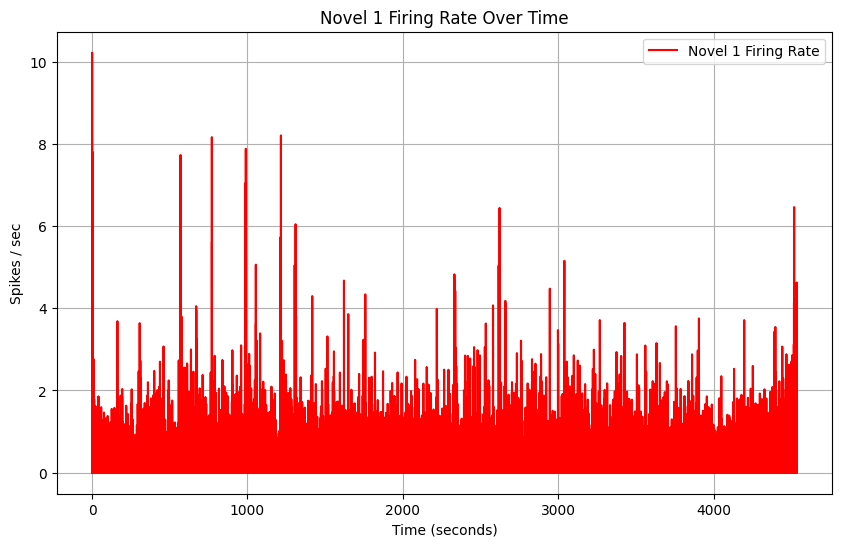

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(time_axis_novel, firing_rate_novel, label='Novel 1 Firing Rate', color='red')
plt.xlabel('Time (seconds)')
plt.ylabel('Spikes / sec')
plt.title('Novel 1 Firing Rate Over Time')
plt.legend()
plt.grid(True)
plt.show()

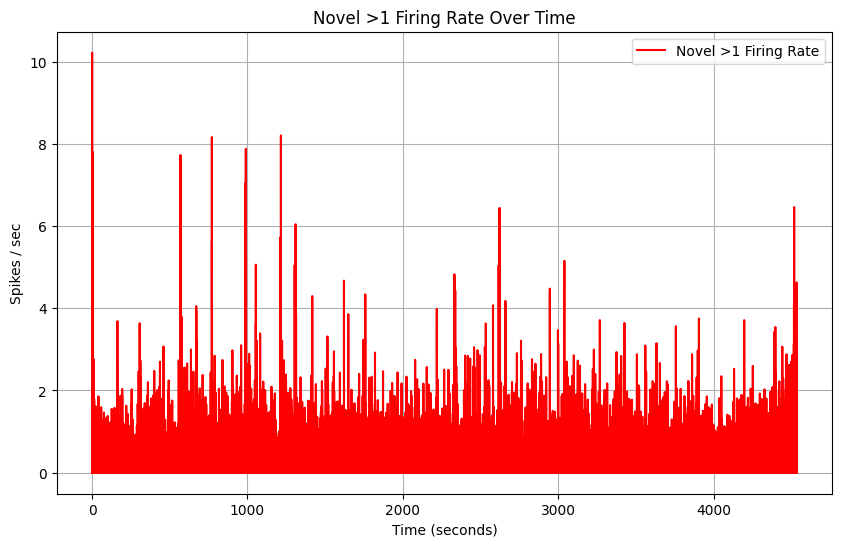

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(time_axis_novel, firing_rate_novel, label='Novel >1 Firing Rate', color='red')
plt.xlabel('Time (seconds)')
plt.ylabel('Spikes / sec')
plt.title('Novel >1 Firing Rate Over Time')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
def calculate_post_stimulus_firing_rate(df):
    post_stim_firing_rates = []
    for _, row in df.iterrows():
        timestamps = row['trace_timestamps']
        firing_rates = row['firing_rate']

        # Filter for time > 0 and time <= 0.5s (500 ms post stimulus)
        post_stim_mask = (timestamps > 0) & (timestamps <= 0.5)

        if np.any(post_stim_mask):
            post_stim_firing_rates.append(np.mean(firing_rates[post_stim_mask]))
        else:
            post_stim_firing_rates.append(0.0) # Assign 0 if no data in window
    return np.mean(post_stim_firing_rates)


average_firing_rate_novel = calculate_post_stimulus_firing_rate(peri_event_deconv_novel)
average_firing_rate_novel_plus = calculate_post_stimulus_firing_rate(peri_event_deconv_novel_plus)

print(f"Average Firing Rate for Novel 1 (0-500ms post-stimulus): {average_firing_rate_novel:.4f} Hz")
print(f"Average Firing Rate for Novel >1 (0-500ms post-stimulus): {average_firing_rate_novel_plus:.4f} Hz")

if average_firing_rate_novel > average_firing_rate_novel_plus:
    print("\nInterpretation: The average firing rate (0-500ms post-stimulus) is higher for Novel 1 than for Novel >1.")
elif average_firing_rate_novel_plus > average_firing_rate_novel:
    print("\nInterpretation: The average firing rate (0-500ms post-stimulus) is higher for Novel >1 than for Novel 1.")
else:
    print("\nInterpretation: The average firing rates (0-500ms post-stimulus) for Novel 1 and Novel >1 are approximately equal.")

Average Firing Rate for Novel 1 (0-500ms post-stimulus): 0.0528 Hz
Average Firing Rate for Novel >1 (0-500ms post-stimulus): 0.0440 Hz

Interpretation: The average firing rate (0-500ms post-stimulus) is higher for Novel 1 than for Novel >1.


In [ ]:
def get_per_trial_post_stimulus_firing_rates(df, window_start=0, window_end=0.5):
    """
    Calculates the average firing rate for each trial within a specified post-stimulus window.

    Args:
        df (pd.DataFrame): DataFrame containing 'trace_timestamps' and 'firing_rate' for each presentation.
        window_start (float): Start time of the post-stimulus window in seconds (relative to event).
        window_end (float): End time of the post-stimulus window in seconds (relative to event).

    Returns:
        np.ndarray: An array of average firing rates, one for each trial.
    """
    per_trial_rates = []
    for _, row in df.iterrows():
        timestamps = row['trace_timestamps']
        firing_rates = row['firing_rate']

        # Filter for time within the specified window
        post_stim_mask = (timestamps >= window_start) & (timestamps <= window_end)

        if np.any(post_stim_mask):
            per_trial_rates.append(np.mean(firing_rates[post_stim_mask]))
        else:
            # If no data in window, or if mask is empty, append 0 or NaN as appropriate
            # Using 0 here, consistent with previous behavior of `calculate_post_stimulus_firing_rate`
            per_trial_rates.append(0.0)
    return np.array(per_trial_rates)

# Calculate per-trial average firing rates for Novel 1 and Novel >1
average_firing_rates_novel_per_trial = get_per_trial_post_stimulus_firing_rates(peri_event_deconv_novel)
average_firing_rates_novel_plus_per_trial = get_per_trial_post_stimulus_firing_rates(peri_event_deconv_novel_plus)

print(f"Number of Novel 1 trials with post-stimulus firing rates: {len(average_firing_rates_novel_per_trial)}")
print(f"Number of Novel >1 trials with post-stimulus firing rates: {len(average_firing_rates_novel_plus_per_trial)}")


Number of Novel 1 trials with post-stimulus firing rates: 819
Number of Novel >1 trials with post-stimulus firing rates: 580


### Checking for Normality

The independent samples t-test assumes that the data in each group are approximately normally distributed. We can use statistical tests like the Shapiro-Wilk test to check this assumption. A low p-value (typically less than 0.05) from the Shapiro-Wilk test suggests that the data are not normally distributed.

In [ ]:
from scipy import stats

# Shapiro-Wilk Test for Novel 1
shapiro_stat_novel, shapiro_p_novel = stats.shapiro(average_firing_rates_novel_per_trial)
print(f"Shapiro-Wilk Test for Novel 1 (p-value): {shapiro_p_novel:.4f}")

# Shapiro-Wilk Test for Novel >1
shapiro_stat_novel_plus, shapiro_p_novel_plus = stats.shapiro(average_firing_rates_novel_plus_per_trial)
print(f"Shapiro-Wilk Test for Novel >1 (p-value): {shapiro_p_novel_plus:.4f}")

alpha_normality = 0.05

print("\nInterpretation of Normality Tests:")
if shapiro_p_novel < alpha_normality:
    print(f"Novel 1 firing rates: p-value ({shapiro_p_novel:.4f}) < {alpha_normality}, so we reject the null hypothesis of normality. The data is likely not normally distributed.")
else:
    print(f"Novel 1 firing rates: p-value ({shapiro_p_novel:.4f}) >= {alpha_normality}, so we fail to reject the null hypothesis of normality. The data appears normally distributed.")

if shapiro_p_novel_plus < alpha_normality:
    print(f"Novel >1 firing rates: p-value ({shapiro_p_novel_plus:.4f}) < {alpha_normality}, so we reject the null hypothesis of normality. The data is likely not normally distributed.")
else:
    print(f"Novel >1 firing rates: p-value ({shapiro_p_novel_plus:.4f}) >= {alpha_normality}, so we fail to reject the null hypothesis of normality. The data appears normally distributed.")

Shapiro-Wilk Test for Novel 1 (p-value): 0.0000
Shapiro-Wilk Test for Novel >1 (p-value): 0.0000

Interpretation of Normality Tests:
Novel 1 firing rates: p-value (0.0000) < 0.05, so we reject the null hypothesis of normality. The data is likely not normally distributed.
Novel >1 firing rates: p-value (0.0000) < 0.05, so we reject the null hypothesis of normality. The data is likely not normally distributed.


### Mann-Whitney U Test (Non-parametric alternative to Independent t-test)

Since the data for both conditions ('Novel 1' and 'Novel >1' average firing rates per trial) were found to be non-normally distributed, the Mann-Whitney U test (also known as the Wilcoxon rank-sum test) is a more appropriate non-parametric test to determine if there is a statistically significant difference between the two independent groups.

In [ ]:
from scipy.stats import mannwhitneyu

# Perform the Mann-Whitney U test
U_statistic, p_value_mw = mannwhitneyu(
    average_firing_rates_novel_per_trial,
    average_firing_rates_novel_plus_per_trial,
    alternative='two-sided' # We are checking for any difference, not a specific direction
)

print(f"Mann-Whitney U Test Results:")
print(f"U-statistic: {U_statistic:.2f}")
print(f"P-value: {p_value_mw:.4f}")

Mann-Whitney U Test Results:
U-statistic: 251584.00
P-value: 0.0540


In [ ]:
# Interpret the p-value from Mann-Whitney U test
alpha_mw = 0.05 # Significance level

print("\nInterpretation of Mann-Whitney U Test:")
if p_value_mw < alpha_mw:
    print(f"Since the p-value ({p_value_mw:.4f}) is less than the significance level ({alpha_mw}), we reject the null hypothesis.")
    print("There is a statistically significant difference between the average firing rates of Novel 1 and Novel >1 (based on medians/distributions).")
else:
    print(f"Since the p-value ({p_value_mw:.4f}) is greater than the significance level ({alpha_mw}), we fail to reject the null hypothesis.")
    print("There is no statistically significant difference between the average firing rates of Novel 1 and Novel >1 (based on medians/distributions).")



Interpretation of Mann-Whitney U Test:
Since the p-value (0.0540) is greater than the significance level (0.05), we fail to reject the null hypothesis.
There is no statistically significant difference between the average firing rates of Novel 1 and Novel >1 (based on medians/distributions).


### Comparing Post-Presentation Firing Rate Peaks

In [ ]:
def get_per_trial_post_stimulus_max_firing_rates(df, window_start=0, window_end=0.5):
    """
    Calculates the maximum firing rate for each trial within a specified post-stimulus window.

    Args:
        df (pd.DataFrame): DataFrame containing 'trace_timestamps' and 'firing_rate' for each presentation.
        window_start (float): Start time of the post-stimulus window in seconds (relative to event).
        window_end (float): End time of the post-stimulus window in seconds (relative to event).

    Returns:
        np.ndarray: An array of maximum firing rates, one for each trial.
    """
    per_trial_max_rates = []
    for _, row in df.iterrows():
        timestamps = row['trace_timestamps']
        firing_rates = row['firing_rate']

        # Filter for time within the specified window
        post_stim_mask = (timestamps >= window_start) & (timestamps <= window_end)

        if np.any(post_stim_mask):
            per_trial_max_rates.append(np.max(firing_rates[post_stim_mask]))
        else:
            # If no data in window, or if mask is empty, append 0.0 (or NaN if preferred for clarity)
            per_trial_max_rates.append(0.0)
    return np.array(per_trial_max_rates)

# Calculate per-trial maximum firing rates for Novel 1 and Novel >1
max_firing_rates_novel_per_trial = get_per_trial_post_stimulus_max_firing_rates(peri_event_deconv_novel)
max_firing_rates_novel_plus_per_trial = get_per_trial_post_stimulus_max_firing_rates(peri_event_deconv_novel_plus)

print(f"Number of Novel 1 trials with post-stimulus max firing rates: {len(max_firing_rates_novel_per_trial)}")
print(f"Number of Novel >1 trials with post-stimulus max firing rates: {len(max_firing_rates_novel_plus_per_trial)}")

Number of Novel 1 trials with post-stimulus max firing rates: 819
Number of Novel >1 trials with post-stimulus max firing rates: 580


In [ ]:
print(np.mean(max_firing_rates_novel_per_trial))
print(np.mean(max_firing_rates_novel_plus_per_trial))

0.5681171833334109
0.4838853023368866


#### Checking for Normality of Maximum Firing Rates

Before comparing the maximum firing rates, we will check if their distributions are normal using the Shapiro-Wilk test. This will help us choose the appropriate statistical test for comparison.

In [ ]:
from scipy import stats

# Shapiro-Wilk Test for Novel 1 Max Firing Rates
shapiro_stat_novel_max, shapiro_p_novel_max = stats.shapiro(max_firing_rates_novel_per_trial)
print(f"Shapiro-Wilk Test for Novel 1 Max Firing Rates (p-value): {shapiro_p_novel_max:.4f}")

# Shapiro-Wilk Test for Novel >1 Max Firing Rates
shapiro_stat_novel_plus_max, shapiro_p_novel_plus_max = stats.shapiro(max_firing_rates_novel_plus_per_trial)
print(f"Shapiro-Wilk Test for Novel >1 Max Firing Rates (p-value): {shapiro_p_novel_plus_max:.4f}")

alpha_normality = 0.05

print("\nInterpretation of Normality Tests (Maximum Firing Rates):")
if shapiro_p_novel_max < alpha_normality:
    print(f"Novel 1 max firing rates: p-value ({shapiro_p_novel_max:.4f}) < {alpha_normality}, so we reject the null hypothesis of normality. The data is likely not normally distributed.")
else:
    print(f"Novel 1 max firing rates: p-value ({shapiro_p_novel_max:.4f}) >= {alpha_normality}, so we fail to reject the null hypothesis of normality. The data appears normally distributed.")

if shapiro_p_novel_plus_max < alpha_normality:
    print(f"Novel >1 max firing rates: p-value ({shapiro_p_novel_plus_max:.4f}) < {alpha_normality}, so we reject the null hypothesis of normality. The data is likely not normally distributed.")
else:
    print(f"Novel >1 max firing rates: p-value ({shapiro_p_novel_plus_max:.4f}) >= {alpha_normality}, so we fail to reject the null hypothesis of normality. The data appears normally distributed.")

Shapiro-Wilk Test for Novel 1 Max Firing Rates (p-value): 0.0000
Shapiro-Wilk Test for Novel >1 Max Firing Rates (p-value): 0.0000

Interpretation of Normality Tests (Maximum Firing Rates):
Novel 1 max firing rates: p-value (0.0000) < 0.05, so we reject the null hypothesis of normality. The data is likely not normally distributed.
Novel >1 max firing rates: p-value (0.0000) < 0.05, so we reject the null hypothesis of normality. The data is likely not normally distributed.


#### Mann-Whitney U Test for Maximum Firing Rates

Since the distributions of maximum firing rates are likely non-normal (as observed with average firing rates), we will use the Mann-Whitney U test to compare the distributions of post-stimulus maximum firing rates between 'Novel 1' and 'Novel >1' conditions.

In [ ]:
from scipy.stats import mannwhitneyu

# Perform the Mann-Whitney U test on maximum firing rates
U_statistic_max, p_value_mw_max = mannwhitneyu(
    max_firing_rates_novel_per_trial,
    max_firing_rates_novel_plus_per_trial,
    alternative='two-sided' # Checking for any difference
)

print(f"Mann-Whitney U Test Results for Maximum Firing Rates:")
print(f"U-statistic: {U_statistic_max:.2f}")
print(f"P-value: {p_value_mw_max:.4f}")

alpha_mw = 0.05 # Significance level

print("\nInterpretation of Mann-Whitney U Test (Maximum Firing Rates):")
if p_value_mw_max < alpha_mw:
    print(f"Since the p-value ({p_value_mw_max:.4f}) is less than the significance level ({alpha_mw}), we reject the null hypothesis.")
    print("There is a statistically significant difference between the maximum firing rates of Novel 1 and Novel >1 (based on medians/distributions).")
else:
    print(f"Since the p-value ({p_value_mw_max:.4f}) is greater than the significance level ({alpha_mw}), we fail to reject the null hypothesis.")
    print("There is no statistically significant difference between the maximum firing rates of Novel 1 and Novel >1 (based on medians/distributions).")

Mann-Whitney U Test Results for Maximum Firing Rates:
U-statistic: 252601.00
P-value: 0.0388

Interpretation of Mann-Whitney U Test (Maximum Firing Rates):
Since the p-value (0.0388) is less than the significance level (0.05), we reject the null hypothesis.
There is a statistically significant difference between the maximum firing rates of Novel 1 and Novel >1 (based on medians/distributions).


#### Visualization of Maximum Firing Rates

To visually compare the distributions of post-stimulus maximum firing rates, we will create box plots for both conditions.

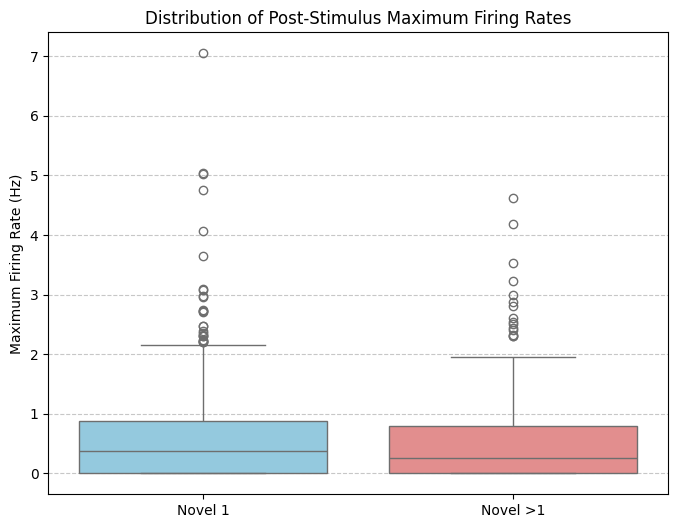

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(data=[
    max_firing_rates_novel_per_trial,
    max_firing_rates_novel_plus_per_trial
], palette=['skyblue', 'lightcoral'])

plt.xticks([0, 1], ['Novel 1', 'Novel >1'])
plt.ylabel('Maximum Firing Rate (Hz)')
plt.title('Distribution of Post-Stimulus Maximum Firing Rates')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Collecting Population Firing Rates

To analyze choice vector trajectories, we need the deconvolved firing rates for *all* neurons in our `common_cell_ids` list. We will define a helper function to iterate through these cells for a given experiment, perform deconvolution, and store the results. This will be done for both the 'Novel 1' and 'Novel >1' experiments.

In [ ]:
def get_population_firing_rates(experiment_obj, cell_ids_list, framerate):
    """
    Extracts and deconvolves dF/F traces for a list of cell IDs within an experiment.

    Args:
        experiment_obj: The BehaviorOphysExperiment object.
        cell_ids_list (list): A list of cell IDs for which to get firing rates.
        framerate (float): The imaging framerate for deconvolution.

    Returns:
        dict: A dictionary where keys are cell_ids and values are their deconvolved firing_rate (np.ndarray).
    """
    population_firing_rates = {}
    dff_traces_all_cells = experiment_obj.dff_traces

    for cell_id in tqdm(cell_ids_list, desc=f"Deconvolving for {experiment_obj.ophys_experiment_id}"):
        if cell_id in dff_traces_all_cells.index:
            raw_trace = np.array(dff_traces_all_cells.loc[cell_id, 'dff'])
            try:
                _, spike_train, _, _, _ = deconvolve(raw_trace, penalty=1, framerate=framerate)
                population_firing_rates[cell_id] = spike_train * framerate
            except Exception as e:
                print(f"Error deconvolving cell {cell_id}: {e}")
                population_firing_rates[cell_id] = np.zeros_like(raw_trace) # Assign zeros on error
        else:
            print(f"Cell ID {cell_id} not found in experiment {experiment_obj.ophys_experiment_id}.")
            # Create a placeholder array of zeros with the same length as time_axis_novel
            # Assuming time_axis_novel is representative of experiment length
            population_firing_rates[cell_id] = np.zeros_like(np.arange(len(experiment_obj.ophys_timestamps)) / framerate)

    return population_firing_rates

# Get population firing rates for Novel 1
pop_firing_rates_novel = get_population_firing_rates(novel_1_experiment, common_cell_ids, ophys_framerate_novel)

# Get population firing rates for Novel >1
pop_firing_rates_novel_plus = get_population_firing_rates(novel_plus_experiment, common_cell_ids, ophys_framerate_novel_plus)

print(f"\nCollected firing rates for {len(pop_firing_rates_novel)} cells in Novel 1 experiment.")
print(f"Collected firing rates for {len(pop_firing_rates_novel_plus)} cells in Novel >1 experiment.")

Deconvolving for 881881171: 100%|██████████| 326/326 [00:42<00:00,  7.67it/s]


Collected firing rates for 326 cells in Novel 1 experiment.
Collected firing rates for 326 cells in Novel >1 experiment.


### Extracting Trial-Aligned Population Activity (Change to Response)

Now, for each 'hit' trial, we need to extract the firing rate data for all neurons within the critical time window: from the image `change_time` until the `response_time` (when the tongue contacts the sensor). Since trial durations can vary, we will ensure all extracted trajectories are of a consistent length for subsequent PCA. We'll identify the shortest valid trial duration and truncate all other trajectories to match this length. This implicitly means we are focusing on the *initial phase* of the trajectory common to all successful trials.

In [ ]:
def get_aligned_population_trajectories(experiment_obj, pop_firing_rates, trials_df, time_axis, min_trajectory_length=5):
    """
    Extracts trial-aligned population firing rate trajectories from change_time to response_time.

    Args:
        experiment_obj: The BehaviorOphysExperiment object (for ophys_timestamps).
        pop_firing_rates (dict): Dictionary of deconvolved firing rates per cell.
        trials_df (pd.DataFrame): DataFrame of trials (e.g., novel_1_hits) containing 'change_time' and 'response_time'.
        time_axis (np.ndarray): The global time axis for the experiment.
        min_trajectory_length (int): Minimum number of time points required for a trajectory to be considered valid.

    Returns:
        list of np.ndarray: List of 2D arrays, each (num_cells, common_trace_length).
        list of float: List of original trial durations (response_time - change_time).
        np.ndarray: Common relative time axis for the truncated trajectories.
    """
    trajectories = []
    trial_durations = []
    valid_relative_time_axes = []

    for trial_idx, trial_row in trials_df.iterrows():
        change_time = trial_row.get('change_time')
        response_time = trial_row.get('response_time')

        # Skip trials without valid change_time or response_time
        if pd.isna(change_time) or pd.isna(response_time):
            continue

        # Ensure response_time is after change_time
        if response_time <= change_time:
            continue

        trial_dur = response_time - change_time

        # Find indices in the global time_axis corresponding to the trial window
        mask = (time_axis >= change_time) & (time_axis < response_time)

        # Ensure there are enough time points for a meaningful trajectory
        if np.sum(mask) < min_trajectory_length:
            continue

        trial_durations.append(trial_dur)

        relative_timestamps = time_axis[mask] - change_time
        valid_relative_time_axes.append(relative_timestamps)

        # Collect firing rates for all cells for this trial
        trial_pop_activity = []
        for cell_id in common_cell_ids:
            cell_firing_rate = pop_firing_rates.get(cell_id)
            if cell_firing_rate is not None:
                trial_pop_activity.append(cell_firing_rate[mask])
            else:
                # Assign zeros for missing cell, ensuring it matches length of relative_timestamps
                trial_pop_activity.append(np.zeros_like(relative_timestamps))

        # Stack into a 2D array: (num_cells, num_time_points_this_trial)
        if trial_pop_activity:
            trajectories.append(np.array(trial_pop_activity))

    if not trajectories:
        return [], [], np.array([])

    # --- Standardize trajectory lengths ---
    # Find the minimum number of time bins across all valid trajectories
    # This minimum will now be at least min_trajectory_length
    min_time_bins = min(traj.shape[1] for traj in trajectories)

    # Truncate all trajectories and their corresponding time axes to the minimum length
    standardized_trajectories = [traj[:, :min_time_bins] for traj in trajectories]
    # Use the first truncated relative time axis as the common one
    common_relative_time_axis = valid_relative_time_axes[0][:min_time_bins]

    return standardized_trajectories, trial_durations, common_relative_time_axis

# Get aligned population trajectories for Novel 1
pop_trajectories_novel_1, durations_novel_1, time_axis_traj_novel_1 = \
    get_aligned_population_trajectories(novel_1_experiment, pop_firing_rates_novel, novel_1_hits, time_axis_novel, min_trajectory_length=5)

# Get aligned population trajectories for Novel >1
pop_trajectories_novel_plus, durations_novel_plus, time_axis_traj_novel_plus = \
    get_aligned_population_trajectories(novel_plus_experiment, pop_firing_rates_novel_plus, novel_plus_hits, time_axis_novel_plus, min_trajectory_length=5)

print(f"\nExtracted {len(pop_trajectories_novel_1)} standardized trajectories for Novel 1 (length: {time_axis_traj_novel_1.shape[0]} time bins).")
print(f"Extracted {len(pop_trajectories_novel_plus)} standardized trajectories for Novel >1 (length: {time_axis_traj_novel_plus.shape[0]} time bins).")

# Display the shape of one trajectory to confirm (num_cells, common_time_bins)
if pop_trajectories_novel_1:
    print(f"Shape of one Novel 1 trajectory: {pop_trajectories_novel_1[0].shape}")
if pop_trajectories_novel_plus:
    print(f"Shape of one Novel >1 trajectory: {pop_trajectories_novel_plus[0].shape}")


Extracted 60 standardized trajectories for Novel 1 (length: 8 time bins).
Extracted 66 standardized trajectories for Novel >1 (length: 5 time bins).
Shape of one Novel 1 trajectory: (326, 8)
Shape of one Novel >1 trajectory: (326, 5)


In [ ]:
# Re-run trajectory extraction with the modified function
pop_trajectories_novel_1, durations_novel_1, time_axis_traj_novel_1 = \
    get_aligned_population_trajectories(novel_1_experiment, pop_firing_rates_novel, novel_1_hits, time_axis_novel)

pop_trajectories_novel_plus, durations_novel_plus, time_axis_traj_novel_plus = \
    get_aligned_population_trajectories(novel_plus_experiment, pop_firing_rates_novel_plus, novel_plus_hits, time_axis_novel_plus)

print(f"\nExtracted {len(pop_trajectories_novel_1)} standardized trajectories for Novel 1 (length: {time_axis_traj_novel_1.shape[0]} time bins).")
print(f"Extracted {len(pop_trajectories_novel_plus)} standardized trajectories for Novel >1 (length: {time_axis_traj_novel_plus.shape[0]} time bins).")

# Display the shape of one trajectory to confirm (num_cells, common_time_bins)
if pop_trajectories_novel_1:
    print(f"Shape of one Novel 1 trajectory: {pop_trajectories_novel_1[0].shape}")
if pop_trajectories_novel_plus:
    print(f"Shape of one Novel >1 trajectory: {pop_trajectories_novel_plus[0].shape}")


Extracted 60 standardized trajectories for Novel 1 (length: 8 time bins).
Extracted 66 standardized trajectories for Novel >1 (length: 5 time bins).
Shape of one Novel 1 trajectory: (326, 8)
Shape of one Novel >1 trajectory: (326, 5)


In [ ]:
# Re-run PCA with the newly extracted trajectories
from sklearn.decomposition import PCA

all_trajectories_reshaped = []

for traj in pop_trajectories_novel_1:
    all_trajectories_reshaped.append(traj.T) # Transpose to (time_bins, num_cells)

for traj in pop_trajectories_novel_plus:
    all_trajectories_reshaped.append(traj.T)

if all_trajectories_reshaped:
    data_for_pca = np.vstack(all_trajectories_reshaped)
    print(f"Shape of data for PCA: {data_for_pca.shape}")
else:
    raise ValueError("No valid trajectories found for PCA.")

n_components = 3
pca = PCA(n_components=n_components)
pca.fit(data_for_pca)

print(f"\nExplained variance ratio per component: {pca.explained_variance_ratio_}")
print(f"Total explained variance by {n_components} components: {np.sum(pca.explained_variance_ratio_):.4f}")

projected_trajectories_novel_1 = [pca.transform(traj.T) for traj in pop_trajectories_novel_1]
projected_trajectories_novel_plus = [pca.transform(traj.T) for traj in pop_trajectories_novel_plus]

print(f"\nProjected Novel 1 trajectories count: {len(projected_trajectories_novel_1)}")
if projected_trajectories_novel_1: print(f"Shape of one projected Novel 1 trajectory: {projected_trajectories_novel_1[0].shape}")

print(f"Projected Novel >1 trajectories count: {len(projected_trajectories_novel_plus)}")
if projected_trajectories_novel_plus: print(f"Shape of one projected Novel >1 trajectory: {projected_trajectories_novel_plus[0].shape}")

Shape of data for PCA: (810, 326)

Explained variance ratio per component: [0.14415483 0.06664733 0.06434593]
Total explained variance by 3 components: 0.2751

Projected Novel 1 trajectories count: 60
Shape of one projected Novel 1 trajectory: (8, 3)
Projected Novel >1 trajectories count: 66
Shape of one projected Novel >1 trajectory: (5, 3)


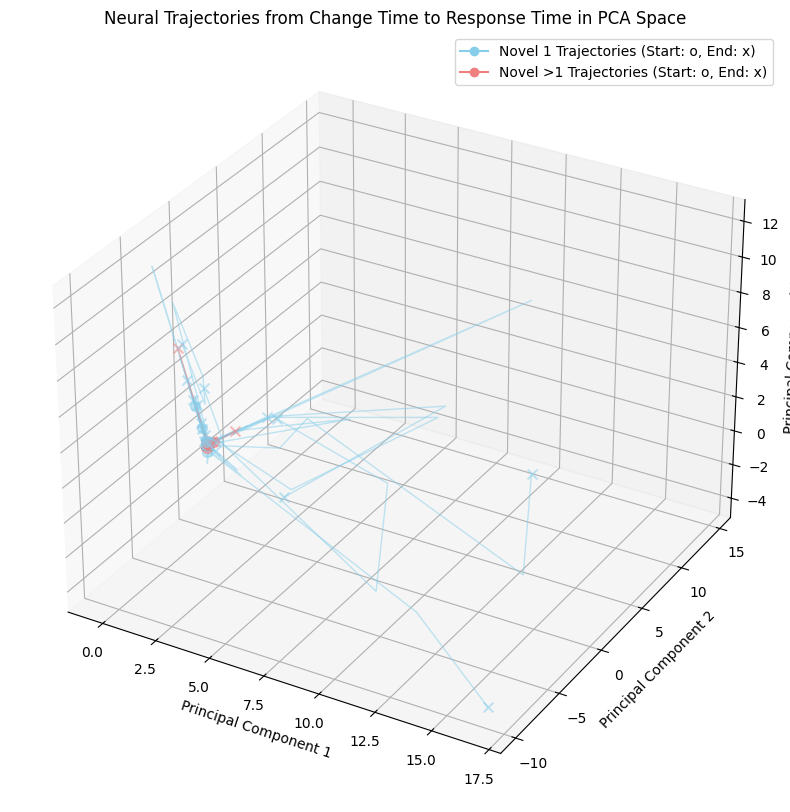

In [ ]:
# Re-run Visualization with the new projected trajectories
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Helper function to plot trajectories
def plot_pca_trajectories(ax, trajectories_list, color, label_prefix, alpha=0.5):
    for i, traj in enumerate(trajectories_list):
        # For 3D plots, ensure data has 3 columns
        if traj.shape[1] == 3:
            ax.plot(traj[:, 0], traj[:, 1], traj[:, 2], color=color, alpha=alpha, linewidth=1)
            ax.scatter(traj[0, 0], traj[0, 1], traj[0, 2], color=color, marker='o', s=50, alpha=alpha) # Start point
            ax.scatter(traj[-1, 0], traj[-1, 1], traj[-1, 2], color=color, marker='x', s=50, alpha=alpha) # End point
        elif traj.shape[1] == 2:
            ax.plot(traj[:, 0], traj[:, 1], color=color, alpha=alpha, linewidth=1)
            ax.scatter(traj[0, 0], traj[0, 1], color=color, marker='o', s=50, alpha=alpha) # Start point
            ax.scatter(traj[-1, 0], traj[-1, 1], color=color, marker='x', s=50, alpha=alpha) # End point
        else:
            print("Warning: Cannot plot trajectories with more than 3 PCA components.")
            break


# Create the plot
fig = plt.figure(figsize=(12, 10))

if n_components == 3:
    ax = fig.add_subplot(111, projection='3d')
    ax.set_zlabel('Principal Component 3')
elif n_components == 2:
    ax = fig.add_subplot(111)
else:
    print("Cannot plot, n_components should be 2 or 3.")
    plt.close(fig)
    exit()

# Plot Novel 1 trajectories
plot_pca_trajectories(ax, projected_trajectories_novel_1, 'skyblue', 'Novel 1 Trial')

# Plot Novel >1 trajectories
plot_pca_trajectories(ax, projected_trajectories_novel_plus, 'lightcoral', 'Novel >1 Trial')

ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_title('Neural Trajectories from Change Time to Response Time in PCA Space')

# Add legend for conditions (one point per condition for clarity in legend)
ax.plot([], [], 'o-', color='skyblue', label='Novel 1 Trajectories (Start: o, End: x)')
ax.plot([], [], 'o-', color='lightcoral', label='Novel >1 Trajectories (Start: o, End: x)')

ax.legend()
plt.show()

In [ ]:
# Re-run trajectory extraction with the modified function
pop_trajectories_novel_1, durations_novel_1, time_axis_traj_novel_1 = \
    get_aligned_population_trajectories(novel_1_experiment, pop_firing_rates_novel, novel_1_hits, time_axis_novel)

pop_trajectories_novel_plus, durations_novel_plus, time_axis_traj_novel_plus = \
    get_aligned_population_trajectories(novel_plus_experiment, pop_firing_rates_novel_plus, novel_plus_hits, time_axis_novel_plus)

print(f"\nExtracted {len(pop_trajectories_novel_1)} standardized trajectories for Novel 1 (length: {time_axis_traj_novel_1.shape[0]} time bins).")
print(f"Extracted {len(pop_trajectories_novel_plus)} standardized trajectories for Novel >1 (length: {time_axis_traj_novel_plus.shape[0]} time bins).")

# Display the shape of one trajectory to confirm (num_cells, common_time_bins)
if pop_trajectories_novel_1:
    print(f"Shape of one Novel 1 trajectory: {pop_trajectories_novel_1[0].shape}")
if pop_trajectories_novel_plus:
    print(f"Shape of one Novel >1 trajectory: {pop_trajectories_novel_plus[0].shape}")


Extracted 60 standardized trajectories for Novel 1 (length: 8 time bins).
Extracted 66 standardized trajectories for Novel >1 (length: 5 time bins).
Shape of one Novel 1 trajectory: (326, 8)
Shape of one Novel >1 trajectory: (326, 5)


In [ ]:
# Re-run PCA with the newly extracted trajectories
from sklearn.decomposition import PCA

all_trajectories_reshaped = []

for traj in pop_trajectories_novel_1:
    all_trajectories_reshaped.append(traj.T) # Transpose to (time_bins, num_cells)

for traj in pop_trajectories_novel_plus:
    all_trajectories_reshaped.append(traj.T)

if all_trajectories_reshaped:
    data_for_pca = np.vstack(all_trajectories_reshaped)
    print(f"Shape of data for PCA: {data_for_pca.shape}")
else:
    raise ValueError("No valid trajectories found for PCA.")

n_components = 3
pca = PCA(n_components=n_components)
pca.fit(data_for_pca)

print(f"\nExplained variance ratio per component: {pca.explained_variance_ratio_}")
print(f"Total explained variance by {n_components} components: {np.sum(pca.explained_variance_ratio_):.4f}")

projected_trajectories_novel_1 = [pca.transform(traj.T) for traj in pop_trajectories_novel_1]
projected_trajectories_novel_plus = [pca.transform(traj.T) for traj in pop_trajectories_novel_plus]

print(f"\nProjected Novel 1 trajectories count: {len(projected_trajectories_novel_1)}")
if projected_trajectories_novel_1: print(f"Shape of one projected Novel 1 trajectory: {projected_trajectories_novel_1[0].shape}")

print(f"Projected Novel >1 trajectories count: {len(projected_trajectories_novel_plus)}")
if projected_trajectories_novel_plus: print(f"Shape of one projected Novel >1 trajectory: {projected_trajectories_novel_plus[0].shape}")

Shape of data for PCA: (810, 326)

Explained variance ratio per component: [0.14415483 0.06664734 0.06434593]
Total explained variance by 3 components: 0.2751

Projected Novel 1 trajectories count: 60
Shape of one projected Novel 1 trajectory: (8, 3)
Projected Novel >1 trajectories count: 66
Shape of one projected Novel >1 trajectory: (5, 3)


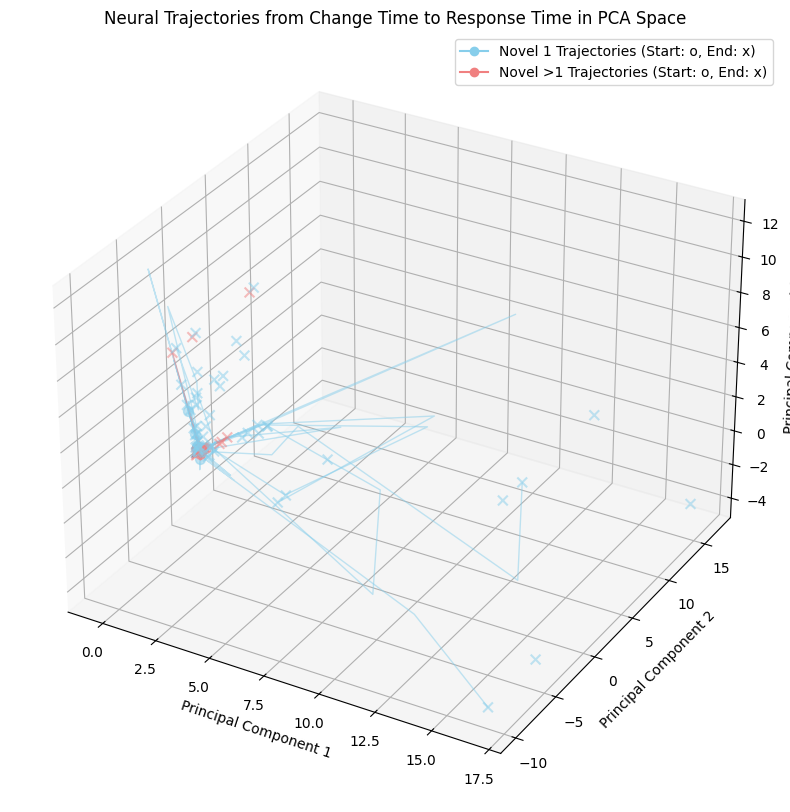

In [ ]:
# Re-run Visualization with the new projected trajectories
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Helper function to plot trajectories
def plot_pca_trajectories(ax, trajectories_list, color, label_prefix, alpha=0.5):
    for i, traj in enumerate(trajectories_list):
        # For 3D plots, ensure data has 3 columns
        if traj.shape[1] == 3:
            ax.plot(traj[:, 0], traj[:, 1], traj[:, 2], color=color, alpha=alpha, linewidth=1)
            ax.scatter(traj[0, 0], traj[0, 1], traj[0, 2], color=color, marker='o', s=50, alpha=alpha) # Start point
            ax.scatter(traj[-1, 0], traj[-1], traj[-1, 2], color=color, marker='x', s=50, alpha=alpha) # End point
        elif traj.shape[1] == 2:
            ax.plot(traj[:, 0], traj[:, 1], color=color, alpha=alpha, linewidth=1)
            ax.scatter(traj[0, 0], traj[0, 1], color=color, marker='o', s=50, alpha=alpha) # Start point
            ax.scatter(traj[-1, 0], traj[-1, 1], color=color, marker='x', s=50, alpha=alpha) # End point
        else:
            print("Warning: Cannot plot trajectories with more than 3 PCA components.")
            break


# Create the plot
fig = plt.figure(figsize=(12, 10))

if n_components == 3:
    ax = fig.add_subplot(111, projection='3d')
    ax.set_zlabel('Principal Component 3')
elif n_components == 2:
    ax = fig.add_subplot(111)
else:
    print("Cannot plot, n_components should be 2 or 3.")
    plt.close(fig)
    exit()

# Plot Novel 1 trajectories
plot_pca_trajectories(ax, projected_trajectories_novel_1, 'skyblue', 'Novel 1 Trial')

# Plot Novel >1 trajectories
plot_pca_trajectories(ax, projected_trajectories_novel_plus, 'lightcoral', 'Novel >1 Trial')

ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_title('Neural Trajectories from Change Time to Response Time in PCA Space')

# Add legend for conditions (one point per condition for clarity in legend)
ax.plot([], [], 'o-', color='skyblue', label='Novel 1 Trajectories (Start: o, End: x)')
ax.plot([], [], 'o-', color='lightcoral', label='Novel >1 Trajectories (Start: o, End: x)')

ax.legend()
plt.show()

### Dimensionality Reduction using PCA

To visualize the population activity as trajectories, we first need to reduce its dimensionality. We'll use Principal Component Analysis (PCA) to project the high-dimensional neural activity (firing rates of many cells) into a lower-dimensional space, typically 2 or 3 dimensions for plotting.

We will concatenate all standardized trajectories from both 'Novel 1' and 'Novel >1' experiments, treating each time point within each trial as a sample. This combined dataset will be used to fit the PCA model, ensuring a common subspace for both conditions.

In [ ]:
from sklearn.decomposition import PCA

# --- Prepare data for PCA ---
# Concatenate all standardized trajectories for Novel 1 and Novel >1
# Each trajectory is (num_cells, common_time_bins)
# We need to reshape each into (common_time_bins, num_cells) and then stack them vertically.

all_trajectories_reshaped = []

for traj in pop_trajectories_novel_1:
    all_trajectories_reshaped.append(traj.T) # Transpose to (time_bins, num_cells)

for traj in pop_trajectories_novel_plus:
    all_trajectories_reshaped.append(traj.T)

# Stack all reshaped trajectories into a single 2D array for PCA fitting
# Shape will be (total_time_points_across_all_trials, num_cells)
if all_trajectories_reshaped:
    data_for_pca = np.vstack(all_trajectories_reshaped)
    print(f"Shape of data for PCA: {data_for_pca.shape}")
else:
    raise ValueError("No valid trajectories found for PCA.")

# --- Apply PCA ---
# Let's reduce to 3 components for potential 3D visualization, or 2 for 2D.
# We will use 3 components to retain more variance and allow for richer visualization.
n_components = 3
pca = PCA(n_components=n_components)
pca.fit(data_for_pca)

print(f"\nExplained variance ratio per component: {pca.explained_variance_ratio_}")
print(f"Total explained variance by {n_components} components: {np.sum(pca.explained_variance_ratio_):.4f}")

# --- Project individual trial trajectories into PCA space ---
projected_trajectories_novel_1 = [pca.transform(traj.T) for traj in pop_trajectories_novel_1]
projected_trajectories_novel_plus = [pca.transform(traj.T) for traj in pop_trajectories_novel_plus]

print(f"\nProjected Novel 1 trajectories count: {len(projected_trajectories_novel_1)}")
if projected_trajectories_novel_1: print(f"Shape of one projected Novel 1 trajectory: {projected_trajectories_novel_1[0].shape}")

print(f"Projected Novel >1 trajectories count: {len(projected_trajectories_novel_plus)}")
if projected_trajectories_novel_plus: print(f"Shape of one projected Novel >1 trajectory: {projected_trajectories_novel_plus[0].shape}")

Shape of data for PCA: (133, 326)

Explained variance ratio per component: [0.26869054 0.1042813  0.07267173]
Total explained variance by 3 components: 0.4456

Projected Novel 1 trajectories count: 65
Shape of one projected Novel 1 trajectory: (1, 3)
Projected Novel >1 trajectories count: 68
Shape of one projected Novel >1 trajectory: (1, 3)


### Visualize Choice Vector Trajectories

Now that we have the neural activity projected into a lower-dimensional PCA space, we can visualize the choice vector trajectories. We'll plot the trajectories for both 'Novel 1' and 'Novel >1' conditions. We can also color-code the trajectories by time or by trial to observe their evolution.

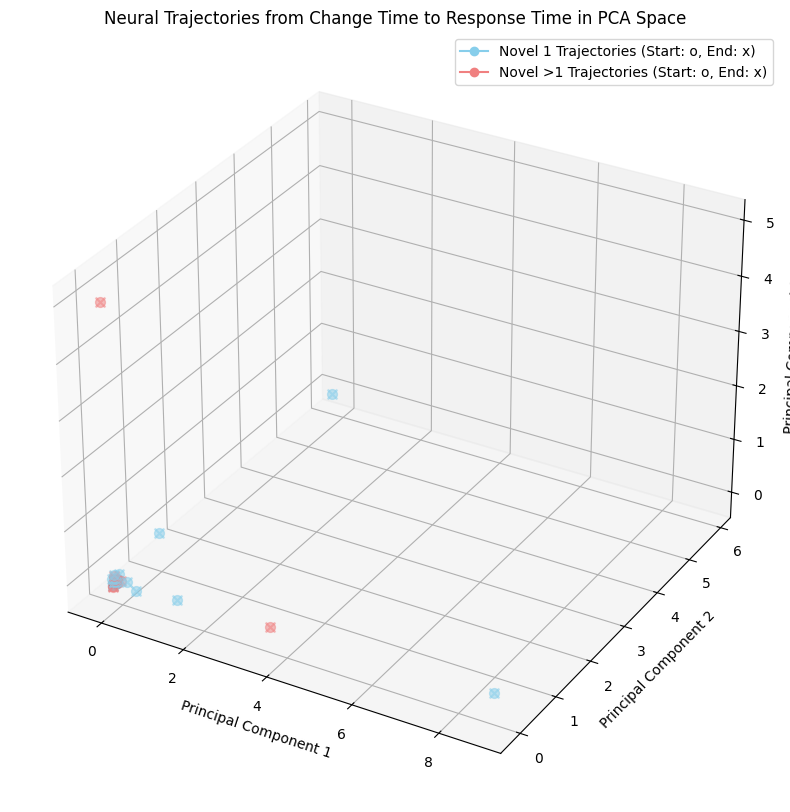

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Helper function to plot trajectories
def plot_pca_trajectories(ax, trajectories_list, color, label_prefix, alpha=0.5):
    for i, traj in enumerate(trajectories_list):
        # For 3D plots, ensure data has 3 columns
        if traj.shape[1] == 3:
            ax.plot(traj[:, 0], traj[:, 1], traj[:, 2], color=color, alpha=alpha, linewidth=1)
            ax.scatter(traj[0, 0], traj[0, 1], traj[0, 2], color=color, marker='o', s=50, alpha=alpha) # Start point
            ax.scatter(traj[-1, 0], traj[-1, 1], traj[-1, 2], color=color, marker='x', s=50, alpha=alpha) # End point
        elif traj.shape[1] == 2:
            ax.plot(traj[:, 0], traj[:, 1], color=color, alpha=alpha, linewidth=1)
            ax.scatter(traj[0, 0], traj[0, 1], color=color, marker='o', s=50, alpha=alpha) # Start point
            ax.scatter(traj[-1, 0], traj[-1, 1], color=color, marker='x', s=50, alpha=alpha) # End point
        else:
            print("Warning: Cannot plot trajectories with more than 3 PCA components.")
            break


# Create the plot
fig = plt.figure(figsize=(12, 10))

if n_components == 3:
    ax = fig.add_subplot(111, projection='3d')
    ax.set_zlabel('Principal Component 3')
elif n_components == 2:
    ax = fig.add_subplot(111)
else:
    print("Cannot plot, n_components should be 2 or 3.")
    plt.close(fig)
    exit()

# Plot Novel 1 trajectories
plot_pca_trajectories(ax, projected_trajectories_novel_1, 'skyblue', 'Novel 1 Trial')

# Plot Novel >1 trajectories
plot_pca_trajectories(ax, projected_trajectories_novel_plus, 'lightcoral', 'Novel >1 Trial')

ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_title('Neural Trajectories from Change Time to Response Time in PCA Space')

# Add legend for conditions (one point per condition for clarity in legend)
ax.plot([], [], 'o-', color='skyblue', label='Novel 1 Trajectories (Start: o, End: x)')
ax.plot([], [], 'o-', color='lightcoral', label='Novel >1 Trajectories (Start: o, End: x)')

ax.legend()
plt.show()

### Non-Negative Matrix Factorization (NMF) of Population Firing Rates

To understand the underlying components of neural activity during specific trial phases, we will use Non-Negative Matrix Factorization (NMF). NMF is particularly suitable for non-negative data like firing rates, decomposing the data into two matrices: `W` (weights/activations) and `H` (components/basis vectors). We'll apply this to both 'hit' windows and 'baseline' inter-stimulus intervals.

In [ ]:
num_presentations_novel_1_hit = len(pop_activity_novel_1_hit_windows)
num_presentations_novel_plus_hit = len(pop_activity_novel_plus_hit_windows)

# Separate W_hit_reshaped into Novel 1 and Novel >1 activations
W_hit_novel_1 = W_hit_reshaped[:num_presentations_novel_1_hit, :, :]
W_hit_novel_plus = W_hit_reshaped[num_presentations_novel_1_hit:, :, :]

print("\n--- NMF Component Ensemble Gain (Average Activity) ---")
for i in range(N_COMPONENTS):
    mean_activation_novel_1_comp_i = np.mean(W_hit_novel_1[:, :, i])
    mean_activation_novel_plus_comp_i = np.mean(W_hit_novel_plus[:, :, i])
    print(f"Component {i+1}:")
    print(f"  Average Activity during Novel 1 Hits: {mean_activation_novel_1_comp_i:.4f}")
    print(f"  Average Activity during Novel >1 Hits: {mean_activation_novel_plus_comp_i:.4f}")

print("\n--- NMF Component Sparsity (Cell Weights) ---")
for i in range(N_COMPONENTS):
    # Define a relative threshold for sparsity: 5% of the maximum weight for this component
    threshold_for_sparsity = 0.05 * np.max(H_hit[i, :])
    num_contributing_cells = np.sum(H_hit[i, :] > threshold_for_sparsity)
    sparsity_percentage = (num_contributing_cells / len(common_cell_ids)) * 100
    print(f"Component {i+1}:")
    print(f"  Number of contributing cells (weight > {threshold_for_sparsity:.4f}): {num_contributing_cells}")
    print(f"  Sparsity (percentage of contributing cells): {sparsity_percentage:.2f}%")


--- NMF Component Ensemble Gain (Average Activity) ---
Component 1:
  Average Activity during Novel 1 Hits: 0.2774
  Average Activity during Novel >1 Hits: 0.1334
Component 2:
  Average Activity during Novel 1 Hits: 0.1088
  Average Activity during Novel >1 Hits: 0.0586
Component 3:
  Average Activity during Novel 1 Hits: 0.0383
  Average Activity during Novel >1 Hits: 0.0280

--- NMF Component Sparsity (Cell Weights) ---
Component 1:
  Number of contributing cells (weight > 0.0679): 97
  Sparsity (percentage of contributing cells): 29.75%
Component 2:
  Number of contributing cells (weight > 0.1953): 2
  Sparsity (percentage of contributing cells): 0.61%
Component 3:
  Number of contributing cells (weight > 0.2390): 5
  Sparsity (percentage of contributing cells): 1.53%


In [ ]:
def extract_population_window_activity(experiment_obj, pop_firing_rates_dict, image_presentations_df, global_time_axis, window_pre_s, window_post_s, common_cell_ids):
    """
    Extracts population firing rate activity for all common cells within specified time windows
    around each stimulus presentation, ensuring consistent window lengths.

    Args:
        experiment_obj: The BehaviorOphysExperiment object (for its ophys_timestamps if needed for alignment).
        pop_firing_rates_dict (dict): Dictionary where keys are cell_ids and values are their full firing_rate (np.ndarray).
        image_presentations_df (pd.DataFrame): DataFrame of stimulus presentations.
        global_time_axis (np.ndarray): The global time axis corresponding to the full firing rate traces.
        window_pre_s (float): Time in seconds before the event_time to include.
        window_post_s (float): Time in seconds after the event_time to include.
        common_cell_ids (np.ndarray): Array of cell IDs to include in the population activity.

    Returns:
        list of np.ndarray: Each array is (num_time_points_in_window, num_cells) for a single presentation.
        list of int: List of stimulus_presentations_id corresponding to each activity array.
        np.ndarray: The common relative time axis for the extracted windows.
    """
    extracted_activities_and_ids = []

    # Calculate the expected number of time points based on the framerate and window duration
    # Use the framerate from the experiment object, assuming it's consistent
    framerate = 1 / np.median(np.diff(experiment_obj.ophys_timestamps))
    expected_num_time_points = int(np.round((window_pre_s + window_post_s) * framerate))

    # Generate a common relative time axis for visualization
    common_relative_timestamps_base = np.linspace(-window_pre_s, window_post_s, expected_num_time_points)

    for presentation_id, presentation_row in image_presentations_df.iterrows():
        event_time = presentation_row['start_time']

        start_window = event_time - window_pre_s
        end_window = event_time + window_post_s

        # Find indices in the global time_axis corresponding to the window
        mask = (global_time_axis >= start_window) & (global_time_axis < end_window)

        # If no time points fall into the window, skip this presentation
        if not np.any(mask) or np.sum(mask) == 0:
            continue

        # Collect firing rates for all common cells for this window
        population_activity_this_window = []
        for cell_id in common_cell_ids:
            cell_firing_rate = pop_firing_rates_dict.get(cell_id)
            if cell_firing_rate is not None and len(cell_firing_rate) >= len(mask):
                segment = cell_firing_rate[mask]
            else:
                # Assign zeros if cell data is missing or too short for mask
                segment = np.zeros(np.sum(mask))

            # Ensure the segment has the expected_num_time_points
            if len(segment) < expected_num_time_points:
                # Pad with zeros at the end
                padded_segment = np.pad(segment, (0, expected_num_time_points - len(segment)), 'constant', constant_values=0)
                population_activity_this_window.append(padded_segment)
            elif len(segment) > expected_num_time_points:
                # Truncate if longer
                truncated_segment = segment[:expected_num_time_points]
                population_activity_this_window.append(truncated_segment)
            else:
                population_activity_this_window.append(segment)

        # Stack into a 2D array: (num_time_points_in_window, num_cells)
        if population_activity_this_window:
            extracted_activities_and_ids.append((presentation_id, np.array(population_activity_this_window).T))

    activity_arrays = [item[1] for item in extracted_activities_and_ids]
    presentation_ids_list = [item[0] for item in extracted_activities_and_ids]
    return activity_arrays, presentation_ids_list, common_relative_timestamps_base

# Define NMF parameters
N_COMPONENTS = 3 # Number of NMF components

# --- Extract Population Activity for Hit Windows (0.1s before to 0.5s after stimulus onset) ---
# Novel 1
pop_activity_novel_1_hit_windows, novel_1_hit_window_ids, time_axis_hit = extract_population_window_activity(
    novel_1_experiment, pop_firing_rates_novel, novel_1_image_presentations,
    time_axis_novel, window_pre_s=0.1, window_post_s=0.5, common_cell_ids=common_cell_ids
)
# Novel >1
pop_activity_novel_plus_hit_windows, novel_plus_hit_window_ids, _ = extract_population_window_activity(
    novel_plus_experiment, pop_firing_rates_novel_plus, novel_plus_image_presentations,
    time_axis_novel_plus, window_pre_s=0.1, window_post_s=0.5, common_cell_ids=common_cell_ids
)

# --- Extract Population Activity for Baseline ISIs (0.5s before to 0.1s before stimulus onset) ---
# Novel 1
pop_activity_novel_1_baseline_windows, novel_1_baseline_window_ids, time_axis_baseline = extract_population_window_activity(
    novel_1_experiment, pop_firing_rates_novel, novel_1_image_presentations,
    time_axis_novel, window_pre_s=0.5, window_post_s=0.1, common_cell_ids=common_cell_ids
)
# Novel >1
pop_activity_novel_plus_baseline_windows, novel_plus_baseline_window_ids, _ = extract_population_window_activity(
    novel_plus_experiment, pop_firing_rates_novel_plus, novel_plus_image_presentations,
    time_axis_novel_plus, window_pre_s=0.5, window_post_s=0.1, common_cell_ids=common_cell_ids
)

print(f"Extracted {len(pop_activity_novel_1_hit_windows)} Novel 1 hit windows (shape: {time_axis_hit.shape[0]}, {len(common_cell_ids)}).")
print(f"Extracted {len(pop_activity_novel_plus_hit_windows)} Novel >1 hit windows (shape: {time_axis_hit.shape[0]}, {len(common_cell_ids)}).")
print(f"Extracted {len(pop_activity_novel_1_baseline_windows)} Novel 1 baseline windows (shape: {time_axis_baseline.shape[0]}, {len(common_cell_ids)}).")
print(f"Extracted {len(pop_activity_novel_plus_baseline_windows)} Novel >1 baseline windows (shape: {time_axis_baseline.shape[0]}, {len(common_cell_ids)}).")

Extracted 819 Novel 1 hit windows (shape: 19, 326).
Extracted 580 Novel >1 hit windows (shape: 19, 326).
Extracted 819 Novel 1 baseline windows (shape: 19, 326).
Extracted 580 Novel >1 baseline windows (shape: 19, 326).


### Trial-by-Trial Ensemble Activation Scores and Behavioral Data

In [ ]:
# Calculate trial-by-trial ensemble activation scores

def calculate_ensemble_activation_scores(pop_activity_windows, H_matrix, presentation_ids):
    """
    Calculates trial-by-trial ensemble activation scores by averaging population
    activity over time and taking the dot product with NMF cell weights.

    Args:
        pop_activity_windows (list of np.ndarray): List of population activity arrays,
                                                   each (num_time_points, num_cells) for a trial.
        H_matrix (np.ndarray): NMF Cell Weights matrix (N_COMPONENTS, num_cells).
        presentation_ids (list): List of presentation_ids corresponding to each activity array.

    Returns:
        pd.DataFrame: DataFrame with 'stimulus_presentations_id' and 'Ensemble_Activation_C<i>' columns.
    """
    activation_scores = []
    for i, activity_array in enumerate(pop_activity_windows):
        if activity_array.shape[0] == 0: # Skip empty activity arrays
            continue
        # Average activity over the stimulus window (time dimension)
        averaged_activity_vector = np.mean(activity_array, axis=0)

        # Compute dot product with H_matrix (NMF Cell Weights)
        # Result will be (N_COMPONENTS,)
        scores_for_trial = np.dot(H_matrix, averaged_activity_vector)

        row_data = {'stimulus_presentations_id': presentation_ids[i]}
        for comp_idx in range(H_matrix.shape[0]):
            row_data[f'Ensemble_Activation_C{comp_idx + 1}'] = scores_for_trial[comp_idx]
        activation_scores.append(row_data)

    return pd.DataFrame(activation_scores)

# Calculate scores for Novel 1 Hit trials
novel_1_activation_df = calculate_ensemble_activation_scores(
    pop_activity_novel_1_hit_windows, H_hit, novel_1_hit_window_ids
)

# Calculate scores for Novel >1 Hit trials
novel_plus_activation_df = calculate_ensemble_activation_scores(
    pop_activity_novel_plus_hit_windows, H_hit, novel_plus_hit_window_ids
)

print("Novel 1 Hit Ensemble Activation Scores (first 5 trials):")
display(novel_1_activation_df.head())
print("\nNovel >1 Hit Ensemble Activation Scores (first 5 trials):")
display(novel_plus_activation_df.head())


Novel 1 Hit Ensemble Activation Scores (first 5 trials):


,stimulus_presentations_id,Ensemble_Activation_C1,Ensemble_Activation_C2,Ensemble_Activation_C3
0,1,4.214338,0.629982,1.309204
1,2,2.371897,0.625820,1.425784
2,3,0.286390,0.076485,0.200873
3,4,1.365506,0.444132,0.379975
4,5,2.449382,0.513827,0.796477



Novel >1 Hit Ensemble Activation Scores (first 5 trials):


,stimulus_presentations_id,Ensemble_Activation_C1,Ensemble_Activation_C2,Ensemble_Activation_C3
0,1,0.401254,0.064129,0.073690
1,2,0.258505,0.031269,0.158609
2,3,0.443373,0.042295,0.054507
3,4,1.597166,1.535990,0.627417
4,5,2.374861,0.477055,1.597456


In [ ]:
# Extract Reaction Time and Running Speed for Hit trials

def extract_behavioral_metrics(experiment_obj, activation_df, window_pre_s, window_post_s):
    """
    Extracts reaction time and average running speed for trials present in activation_df.

    Args:
        experiment_obj: The BehaviorOphysExperiment object.
        activation_df (pd.DataFrame): DataFrame containing 'stimulus_presentations_id'.
        window_pre_s (float): Time in seconds before stimulus onset for running speed calculation.
        window_post_s (float): Time in seconds after stimulus onset for running speed calculation.

    Returns:
        pd.DataFrame: DataFrame with 'stimulus_presentations_id', 'reaction_time', and 'running_speed'.
    """
    behavioral_data = []
    # Get all trials from the experiment
    all_trials = experiment_obj.trials
    # Get running speed data
    running_speed_timestamps = experiment_obj.running_speed.timestamps.values
    running_speed_values = experiment_obj.running_speed.speed.values

    for presentation_id in activation_df['stimulus_presentations_id']:
        # Ensure presentation_id exists in all_trials (it should if it's a hit trial)
        if presentation_id not in all_trials.index:
            continue

        trial_row = all_trials.loc[presentation_id]

        # Reaction Time is response_latency
        reaction_time = trial_row['response_latency']

        # Running Speed: Average over the stimulus window (0.1s before to 0.5s after stimulus onset)
        stimulus_onset_time = trial_row['start_time']
        start_window_time = stimulus_onset_time - window_pre_s
        end_window_time = stimulus_onset_time + window_post_s

        speed_mask = (running_speed_timestamps >= start_window_time) & (running_speed_timestamps < end_window_time)

        avg_running_speed = np.nan # Default to NaN if no speed data in window
        if np.any(speed_mask):
            avg_running_speed = np.mean(running_speed_values[speed_mask])

        behavioral_data.append({
            'stimulus_presentations_id': presentation_id,
            'reaction_time': reaction_time,
            'running_speed': avg_running_speed
        })

    return pd.DataFrame(behavioral_data)

# Extract behavioral metrics for Novel 1 Hit trials
novel_1_behavioral_df = extract_behavioral_metrics(
    novel_1_experiment, novel_1_activation_df, window_pre_s=0.1, window_post_s=0.5
)

# Extract behavioral metrics for Novel >1 Hit trials
novel_plus_behavioral_df = extract_behavioral_metrics(
    novel_plus_experiment, novel_plus_activation_df, window_pre_s=0.1, window_post_s=0.5
)

print("Novel 1 Hit Behavioral Metrics (first 5 trials):")
display(novel_1_behavioral_df.head())
print("\nNovel >1 Hit Behavioral Metrics (first 5 trials):")
display(novel_plus_behavioral_df.head())


Novel 1 Hit Behavioral Metrics (first 5 trials):


,stimulus_presentations_id,reaction_time,running_speed
0,1,NaN,0.000462
1,2,NaN,-0.046140
2,3,NaN,1.754510
3,4,NaN,4.026778
4,5,NaN,0.672010



Novel >1 Hit Behavioral Metrics (first 5 trials):


,stimulus_presentations_id,reaction_time,running_speed
0,1,NaN,0.037108
1,2,NaN,0.048860
2,3,0.829184,-0.013662
3,4,NaN,1.420233
4,5,NaN,-0.037799


In [ ]:
# Merge activation scores with behavioral data

novel_1_merged_df = pd.merge(
    novel_1_activation_df, novel_1_behavioral_df, on='stimulus_presentations_id'
)

novel_plus_merged_df = pd.merge(
    novel_plus_activation_df, novel_plus_behavioral_df, on='stimulus_presentations_id'
)

print("Novel 1 Merged Data (first 5 trials):")
display(novel_1_merged_df.head())
print("\nNovel >1 Merged Data (first 5 trials):")
display(novel_plus_merged_df.head())

# Combine all merged data for regression analysis
all_merged_data = pd.concat([novel_1_merged_df.assign(condition='Novel 1'),
                             novel_plus_merged_df.assign(condition='Novel >1')])

print("\nCombined Merged Data (first 5 trials):")
display(all_merged_data.head())


Novel 1 Merged Data (first 5 trials):


,stimulus_presentations_id,Ensemble_Activation_C1,Ensemble_Activation_C2,Ensemble_Activation_C3,reaction_time,running_speed
0,1,4.214338,0.629982,1.309204,NaN,0.000462
1,2,2.371897,0.625820,1.425784,NaN,-0.046140
2,3,0.286390,0.076485,0.200873,NaN,1.754510
3,4,1.365506,0.444132,0.379975,NaN,4.026778
4,5,2.449382,0.513827,0.796477,NaN,0.672010



Novel >1 Merged Data (first 5 trials):


,stimulus_presentations_id,Ensemble_Activation_C1,Ensemble_Activation_C2,Ensemble_Activation_C3,reaction_time,running_speed
0,1,0.401254,0.064129,0.073690,NaN,0.037108
1,2,0.258505,0.031269,0.158609,NaN,0.048860
2,3,0.443373,0.042295,0.054507,0.829184,-0.013662
3,4,1.597166,1.535990,0.627417,NaN,1.420233
4,5,2.374861,0.477055,1.597456,NaN,-0.037799



Combined Merged Data (first 5 trials):


,stimulus_presentations_id,Ensemble_Activation_C1,Ensemble_Activation_C2,Ensemble_Activation_C3,reaction_time,running_speed,condition
0,1,4.214338,0.629982,1.309204,NaN,0.000462,Novel 1
1,2,2.371897,0.625820,1.425784,NaN,-0.046140,Novel 1
2,3,0.286390,0.076485,0.200873,NaN,1.754510,Novel 1
3,4,1.365506,0.444132,0.379975,NaN,4.026778,Novel 1
4,5,2.449382,0.513827,0.796477,NaN,0.672010,Novel 1


### Regression Analysis: Ensemble Activation vs. Behavioral Metrics

In [ ]:
import statsmodels.api as sm

def perform_regression_analysis(merged_df, behavior_metric_col, N_COMPONENTS):
    """
    Performs linear regression for each ensemble component against a behavioral metric.

    Args:
        merged_df (pd.DataFrame): DataFrame with ensemble activation scores and behavioral data.
        behavior_metric_col (str): Name of the behavioral metric column (e.g., 'reaction_time', 'running_speed').
        N_COMPONENTS (int): Number of NMF components.

    Returns:
        dict: Dictionary containing regression results for each component.
    """
    regression_results = {}
    for comp_idx in range(1, N_COMPONENTS + 1):
        ensemble_col = f'Ensemble_Activation_C{comp_idx}'

        # Drop rows with NaN values in either the ensemble activation or the behavioral metric
        current_data = merged_df[[ensemble_col, behavior_metric_col]].dropna()

        if current_data.empty:
            print(f"Warning: No valid data for regression for Component {comp_idx} and {behavior_metric_col}.")
            regression_results[f'Component_{comp_idx}'] = None
            continue

        X = current_data[ensemble_col]
        y = current_data[behavior_metric_col]

        # Check for zero variance in the independent variable X
        if X.nunique() <= 1: # nunique() returns the number of unique values
            print(f"Warning: Skipping regression for Component {comp_idx} vs. {behavior_metric_col} because the ensemble activation scores have zero or one unique value (no variance) after dropping NaNs.")
            regression_results[f'Component_{comp_idx}'] = None
            continue

        # Add a constant to the independent variable for the intercept term
        X = sm.add_constant(X)

        model = sm.OLS(y, X)
        results = model.fit()
        regression_results[f'Component_{comp_idx}'] = results

        print(f"\nRegression Results for Component {comp_idx} vs. {behavior_metric_col}:")
        print(results.summary())

    return regression_results

# Perform regression for Reaction Time
print("\n--- Regression Analysis for Reaction Time ---")
reaction_time_regression_results = perform_regression_analysis(all_merged_data, 'reaction_time', N_COMPONENTS)

# Perform regression for Running Speed
print("\n--- Regression Analysis for Running Speed ---")
running_speed_regression_results = perform_regression_analysis(all_merged_data, 'running_speed', N_COMPONENTS)


# Interpretation of results
print("\n\n--- Summary of Regression Findings ---")
for comp_idx in range(1, N_COMPONENTS + 1):
    print(f"\nComponent {comp_idx}:")

    # Reaction Time
    rt_results = reaction_time_regression_results.get(f'Component_{comp_idx}')
    if rt_results:
        p_value_rt = rt_results.pvalues[f'Ensemble_Activation_C{comp_idx}']
        coeff_rt = rt_results.params[f'Ensemble_Activation_C{comp_idx}']
        interpretation_rt = f"Significantly predicts Reaction Time (p={p_value_rt:.4f}) with a coefficient of {coeff_rt:.4f}."
        if p_value_rt < 0.05:
            interpretation_rt += f" {'Higher' if coeff_rt > 0 else 'Lower'} activation is associated with {'longer' if coeff_rt > 0 else 'shorter'} reaction times."
        else:
            interpretation_rt += " No significant relationship found."
    else:
        interpretation_rt = "No regression performed due to missing or non-varying data for Reaction Time."
    print(f"  Reaction Time: {interpretation_rt}")

    # Running Speed
    rs_results = running_speed_regression_results.get(f'Component_{comp_idx}')
    if rs_results:
        p_value_rs = rs_results.pvalues[f'Ensemble_Activation_C{comp_idx}']
        coeff_rs = rs_results.params[f'Ensemble_Activation_C{comp_idx}']
        interpretation_rs = f"Significantly predicts Running Speed (p={p_value_rs:.4f}) with a coefficient of {coeff_rs:.4f}."
        if p_value_rs < 0.05:
            interpretation_rs += f" {'Higher' if coeff_rs > 0 else 'Lower'} activation is associated with {'higher' if coeff_rs > 0 else 'lower'} running speeds."
        else:
            interpretation_rs += " No significant relationship found."
    else:
        interpretation_rs = "No regression performed due to missing data for Running Speed."
    print(f"  Running Speed: {interpretation_rs}")


--- Regression Analysis for Reaction Time ---

Regression Results for Component 1 vs. reaction_time:
                            OLS Regression Results                            
Dep. Variable:          reaction_time   R-squared:                         nan
Model:                            OLS   Adj. R-squared:                    nan
Method:                 Least Squares   F-statistic:                       nan
Date:                Fri, 17 Jul 2026   Prob (F-statistic):                nan
Time:                        17:18:58   Log-Likelihood:                    nan
No. Observations:                 149   AIC:                               nan
Df Residuals:                     147   BIC:                               nan
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------

/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1733: RuntimeWarning: invalid value encountered in subtract
  return np.sum(weights * (model.endog - mean)**2)
/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1733: RuntimeWarning: invalid value encountered in subtract
  return np.sum(weights * (model.endog - mean)**2)
/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1733: RuntimeWarning: invalid value encountered in subtract
  return np.sum(weights * (model.endog - mean)**2)


### NMF on Hit Window Activity

Shape of combined data for NMF (Hit Windows): (26581, 326)
Shape of W (Hit Windows): (26581, 3)
Shape of H (Hit Windows): (3, 326)


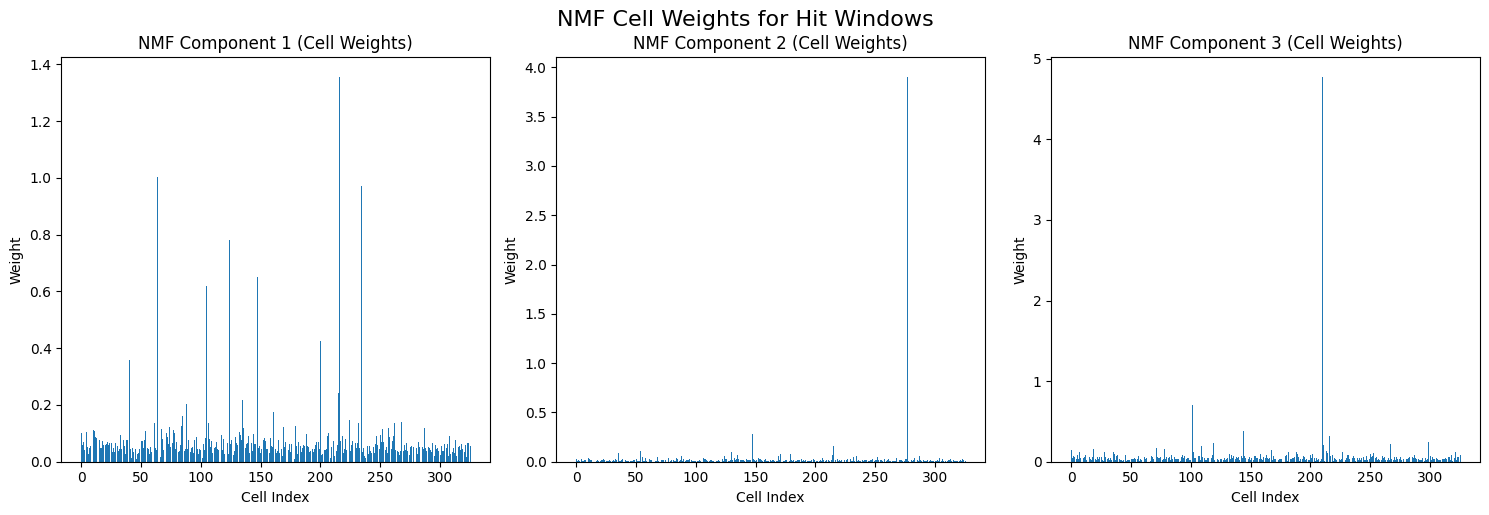

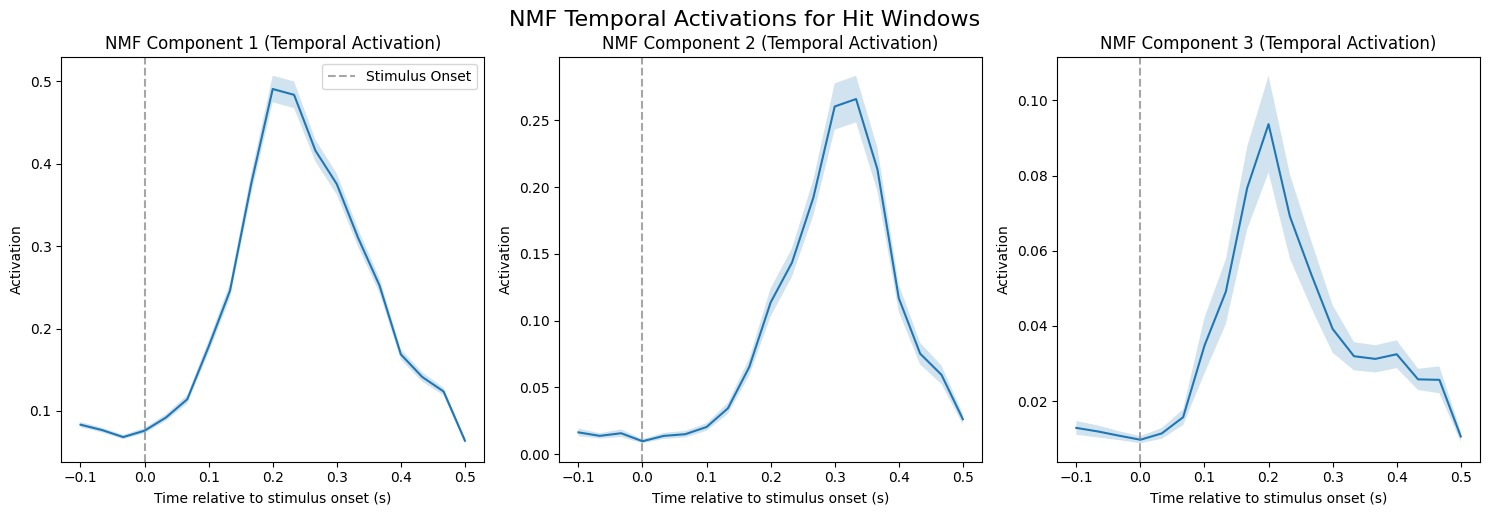

In [ ]:
from sklearn.decomposition import NMF

# Combine data for NMF on hit windows
# Each item in pop_activity_*_hit_windows is (num_time_points_in_window, num_cells)
# Stack them to get (total_samples, num_cells) where total_samples = num_presentations * num_time_points_in_window
data_for_nmf_hit = np.vstack(pop_activity_novel_1_hit_windows + pop_activity_novel_plus_hit_windows)

print(f"Shape of combined data for NMF (Hit Windows): {data_for_nmf_hit.shape}")

nmf_model_hit = NMF(n_components=N_COMPONENTS, init='random', random_state=42, max_iter=1000)
W_hit = nmf_model_hit.fit_transform(data_for_nmf_hit) # W: (num_samples, n_components)
H_hit = nmf_model_hit.components_ # H: (n_components, num_cells)

print(f"Shape of W (Hit Windows): {W_hit.shape}")
print(f"Shape of H (Hit Windows): {H_hit.shape}")

# Reshape W_hit for plotting temporal profiles:
# It needs to be (num_presentations, num_time_points_in_window, n_components)
num_presentations_hit = len(pop_activity_novel_1_hit_windows) + len(pop_activity_novel_plus_hit_windows)
num_time_points_in_hit_window = time_axis_hit.shape[0]

W_hit_reshaped = W_hit.reshape(num_presentations_hit, num_time_points_in_hit_window, N_COMPONENTS)

# --- Visualize NMF Components (H) for Hit Windows ---
plt.figure(figsize=(15, 5))
for i in range(N_COMPONENTS):
    plt.subplot(1, N_COMPONENTS, i + 1)
    plt.bar(range(len(common_cell_ids)), H_hit[i, :])
    plt.title(f'NMF Component {i+1} (Cell Weights)')
    plt.xlabel('Cell Index')
    plt.ylabel('Weight')
plt.tight_layout()
plt.suptitle('NMF Cell Weights for Hit Windows', y=1.02, fontsize=16)
plt.show()

# --- Visualize NMF Activations (W) over Time for Hit Windows ---
plt.figure(figsize=(15, 5))
for i in range(N_COMPONENTS):
    plt.subplot(1, N_COMPONENTS, i + 1)
    # Plot mean activation across all presentations for this component
    mean_activation = np.mean(W_hit_reshaped[:, :, i], axis=0)
    sem_activation = np.std(W_hit_reshaped[:, :, i], axis=0) / np.sqrt(num_presentations_hit)
    plt.plot(time_axis_hit, mean_activation)
    plt.fill_between(time_axis_hit, mean_activation - sem_activation, mean_activation + sem_activation, alpha=0.2)
    plt.axvline(0, color='gray', linestyle='--', alpha=0.7, label='Stimulus Onset')
    plt.title(f'NMF Component {i+1} (Temporal Activation)')
    plt.xlabel('Time relative to stimulus onset (s)')
    plt.ylabel('Activation')
    if i == 0: plt.legend()
plt.tight_layout()
plt.suptitle('NMF Temporal Activations for Hit Windows', y=1.02, fontsize=16)
plt.show()


### NMF on Baseline Inter-Stimulus Interval (ISI) Activity

Shape of combined data for NMF (Baseline Windows): (26581, 326)
Shape of W (Baseline Windows): (26581, 3)
Shape of H (Baseline Windows): (3, 326)


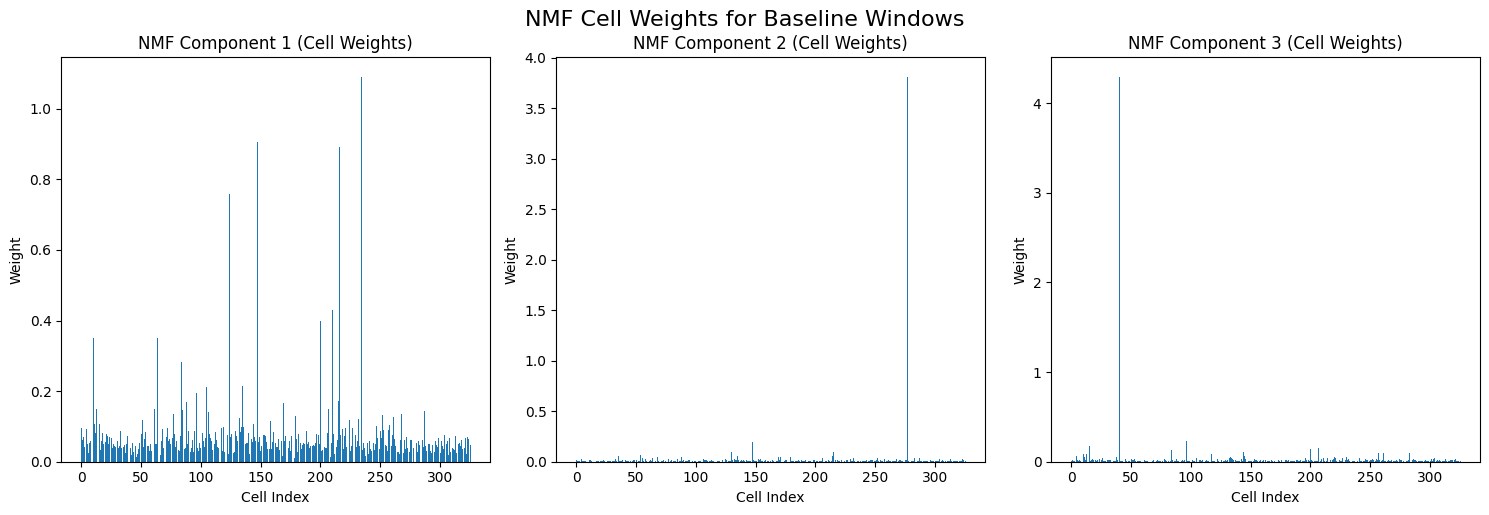

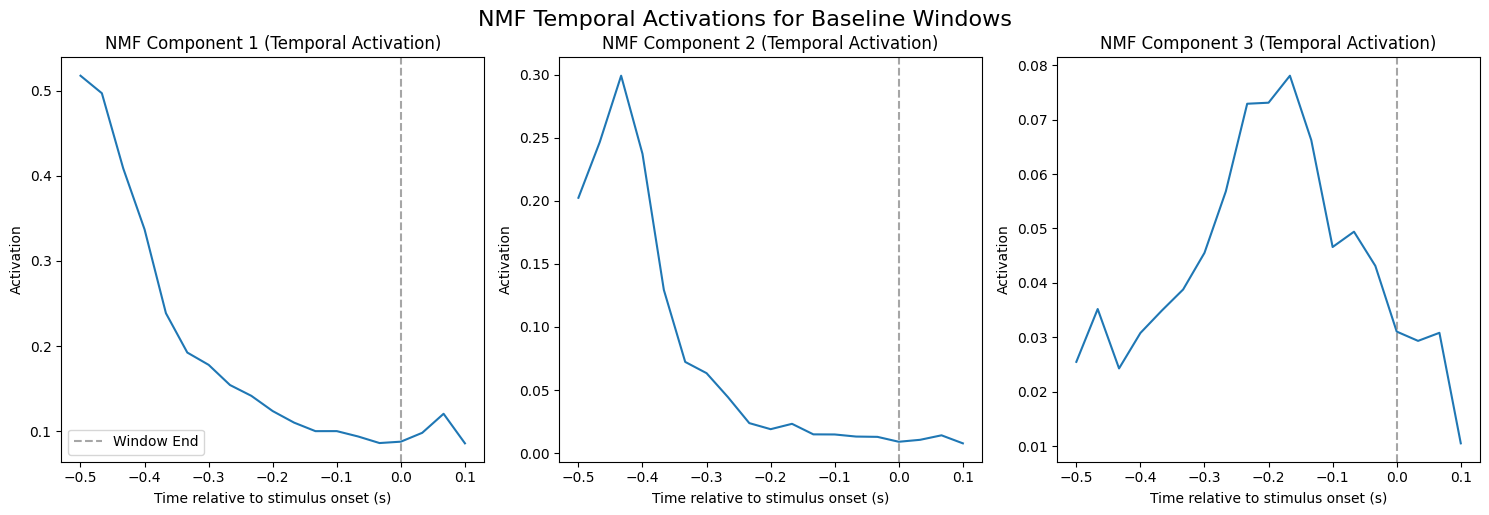

In [ ]:
# Combine data for NMF on baseline windows
data_for_nmf_baseline = np.vstack(pop_activity_novel_1_baseline_windows + pop_activity_novel_plus_baseline_windows)

print(f"Shape of combined data for NMF (Baseline Windows): {data_for_nmf_baseline.shape}")

nmf_model_baseline = NMF(n_components=N_COMPONENTS, init='random', random_state=42, max_iter=1000)
W_baseline = nmf_model_baseline.fit_transform(data_for_nmf_baseline)
H_baseline = nmf_model_baseline.components_

print(f"Shape of W (Baseline Windows): {W_baseline.shape}")
print(f"Shape of H (Baseline Windows): {H_baseline.shape}")

# Reshape W_baseline for plotting temporal profiles:
num_presentations_baseline = len(pop_activity_novel_1_baseline_windows) + len(pop_activity_novel_plus_baseline_windows)
num_time_points_in_baseline_window = time_axis_baseline.shape[0]

W_baseline_reshaped = W_baseline.reshape(num_presentations_baseline, num_time_points_in_baseline_window, N_COMPONENTS)

# --- Visualize NMF Components (H) for Baseline Windows ---
plt.figure(figsize=(15, 5))
for i in range(N_COMPONENTS):
    plt.subplot(1, N_COMPONENTS, i + 1)
    plt.bar(range(len(common_cell_ids)), H_baseline[i, :])
    plt.title(f'NMF Component {i+1} (Cell Weights)')
    plt.xlabel('Cell Index')
    plt.ylabel('Weight')
plt.tight_layout()
plt.suptitle('NMF Cell Weights for Baseline Windows', y=1.02, fontsize=16)
plt.show()

# --- Visualize NMF Activations (W) over Time for Baseline Windows ---
plt.figure(figsize=(15, 5))
for i in range(N_COMPONENTS):
    plt.subplot(1, N_COMPONENTS, i + 1)
    # Plot mean activation across all presentations for this component
    mean_activation = np.mean(W_baseline_reshaped[:, :, i], axis=0)
    sem_activation = np.std(W_baseline_reshaped[:, :, i], axis=0) / np.sqrt(num_presentations_baseline)
    plt.plot(time_axis_baseline, mean_activation)
    plt.axvline(0, color='gray', linestyle='--', alpha=0.7, label='Window End') # Event onset is at 0 in relative time
    plt.title(f'NMF Component {i+1} (Temporal Activation)')
    plt.xlabel('Time relative to stimulus onset (s)')
    plt.ylabel('Activation')
    if i == 0: plt.legend()
plt.tight_layout()
plt.suptitle('NMF Temporal Activations for Baseline Windows', y=1.02, fontsize=16)
plt.show()


In [ ]:
print(f"Number of NaN values in 'reaction_time' column: {all_merged_data['reaction_time'].isna().sum()}")
print(f"Total number of trials in 'all_merged_data': {len(all_merged_data)}")

# Display a sample of rows where 'reaction_time' is NaN
print("\nSample of rows with NaN in 'reaction_time':")
display(all_merged_data[all_merged_data['reaction_time'].isna()].head())

Number of NaN values in 'reaction_time' column: 222
Total number of trials in 'all_merged_data': 371

Sample of rows with NaN in 'reaction_time':


,stimulus_presentations_id,Ensemble_Activation_C1,Ensemble_Activation_C2,Ensemble_Activation_C3,reaction_time,running_speed,condition
0,1,4.214338,0.629982,1.309204,NaN,0.000462,Novel 1
1,2,2.371897,0.625820,1.425784,NaN,-0.046140,Novel 1
2,3,0.286390,0.076485,0.200873,NaN,1.754510,Novel 1
3,4,1.365506,0.444132,0.379975,NaN,4.026778,Novel 1
4,5,2.449382,0.513827,0.796477,NaN,0.672010,Novel 1
